# Fine-tuning de Transformers para tres problemas de NLP

**Emociones en comentarios de Reddit · Habilidades en ofertas de empleo · Desintoxicación de texto**

Proyecto 2 del curso *Fundamentos de Procesamiento de Lenguaje Natural*, Ingeniería de Sistemas, Universidad de
Antioquia (Prof. Antonio Jesús Tamayo Herrera, Ph.D.). Autor: **Jefferson Espejo**.

En este notebook hago *fine-tuning* de tres modelos Transformer pre-entrenados de Hugging Face, uno por cada
familia de problemas de NLP:

| Parte | Tipo de problema | Dataset | Tarea | Modelo |
| :-: | :--- | :--- | :--- | :--- |
| **1** | Clasificación de secuencias (multi-etiqueta) | [GoEmotions](https://huggingface.co/datasets/google-research-datasets/go_emotions) | Detectar cuáles de 27 emociones + neutral expresa un comentario | `roberta-base` |
| **2** | Etiquetado de secuencias | [SkillSpan](https://huggingface.co/datasets/jjzha/skillspan) | Marcar habilidades y conocimientos en ofertas de empleo | BERT vs. JobBERT vs. DeBERTa-v3 |
| **3** | Sequence-to-sequence | [ParaDetox](https://huggingface.co/datasets/s-nlp/paradetox) | Reescribir comentarios tóxicos de forma respetuosa | `bart-base` |

Las tres partes siguen la misma estructura: **descripción de la base de datos → análisis exploratorio →
preparación de los datos → búsqueda de hiperparámetros sobre un *sample* → entrenamiento con la data completa →
evaluación del mejor modelo (contra una línea base clásica) → conclusiones**.

**Contenido**

0. Configuración general
1. Parte 1 · Clasificación de secuencias. Detección de emociones (multi-etiqueta)
2. Parte 2 · Etiquetado de secuencias. Extracción de habilidades en ofertas de empleo
3. Parte 3 · Sequence-to-sequence. Desintoxicación de texto (transferencia de estilo)
4. Resumen de resultados y conclusiones generales

> Recomendado: ejecutar en Google Colab con GPU (*Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*).
> Cada parte importa y define todo lo que usa, así que también se puede volver a ejecutar una parte sola desde su
> primera celda (después de la configuración general).

## 0. Configuración general

Colab ya trae `torch`, `transformers` y `datasets`; instalamos solo lo que falte.

La variable de entorno `SMOKE=1` activa un **modo de verificación**: todo el notebook corre en pocos minutos con
muestras diminutas, útil para comprobar que el código funciona antes de lanzar los entrenamientos largos. Sus
métricas no son representativas.

In [1]:
import importlib.util

REQUIRED = ["transformers", "datasets", "accelerate", "sklearn", "seqeval", "sacrebleu", "seaborn",
            "sentencepiece", "google"]
if any(importlib.util.find_spec(pkg) is None for pkg in REQUIRED):
    %pip install -q transformers datasets accelerate scikit-learn seqeval sacrebleu seaborn sentencepiece protobuf

In [2]:
import os

import torch

SMOKE = os.environ.get("SMOKE", "0") == "1"
FINAL_RESULTS = []  # cada parte agrega aquí sus métricas finales para el resumen de la sección 4
print(f"SMOKE = {SMOKE}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible (se usará CPU)")

SMOKE = False
GPU: NVIDIA GeForce RTX 5070 Ti


## Parte 1 · Clasificación de secuencias. Detección de emociones (multi-etiqueta)

**Problema:** dado un comentario de Reddit en inglés, detectar **qué emociones expresa** entre 27 emociones + `neutral`.
Un mismo comentario puede expresar **varias emociones a la vez** (p. ej. *gratitud* y *alegría*), por lo que es
un problema de clasificación **multi-etiqueta**, más difícil e interesante que el clásico positivo/negativo.

**Dataset:** [GoEmotions](https://huggingface.co/datasets/google-research-datasets/go_emotions) (Demszky et al., 2020, Google Research).
**Modelo base:** [`FacebookAI/roberta-base`](https://huggingface.co/FacebookAI/roberta-base), un modelo tipo **BERT** (encoder).


### 1.1 Configuración e importaciones

Cada parte importa lo que usa, para que se pueda volver a ejecutar desde aquí sin depender de las otras.

In [3]:
import gc
import os
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import Sequence, Value, load_dataset
from sklearn.metrics import classification_report, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

SMOKE = os.environ.get("SMOKE", "0") == "1"  # True = corrida rápida de verificación
SEED = 42
MODEL_NAME = "FacebookAI/roberta-base"
MAX_LENGTH = 64           # los comentarios de Reddit son cortos (ver EDA)
OUTPUT_DIR = "outputs/goemotions"
PUSH_TO_HUB = False       # True para publicar el modelo en tu cuenta de Hugging Face
HF_REPO_ID = "jeffespejo/roberta-base-goemotions-udea"

set_seed(SEED)
# transformers 5 eliminó `warmup_ratio`; ahora `warmup_steps` acepta una fracción de los pasos totales.
import inspect
WARMUP = ({"warmup_ratio": 0.1} if "warmup_ratio" in inspect.signature(TrainingArguments).parameters
          else {"warmup_steps": 0.1})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()
print(f"Dispositivo: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"SMOKE = {SMOKE}")

Dispositivo: cuda (NVIDIA GeForce RTX 5070 Ti)
SMOKE = False


### 1.2 Descripción de la base de datos

| Aspecto | Descripción |
|---|---|
| **Dominio** | Comentarios de Reddit (2005–2019) en inglés, de comunidades muy variadas. Los nombres propios y religiones se reemplazaron por `[NAME]` y `[RELIGION]`. |
| **Tipo de problema** | Clasificación de secuencias **multi-etiqueta**: cada comentario tiene **una o más** de 28 etiquetas. |
| **Entrada (X)** | `text`: un comentario corto (normalmente 1–2 frases), con jerga, emojis e ironía típicos de Reddit. |
| **Salida (y)** | `labels`: lista de emociones presentes. 27 emociones (*admiration, amusement, anger, annoyance, approval, caring, confusion, curiosity, desire, disappointment, disapproval, disgust, embarrassment, excitement, fear, gratitude, grief, joy, love, nervousness, optimism, pride, realization, relief, remorse, sadness, surprise*) + `neutral`. |
| **Tamaño** | 43.410 comentarios de entrenamiento, 5.426 de validación y 5.427 de prueba (versión `simplified`). |
| **Cómo se etiquetó** | Entre 3 y 5 anotadores por comentario; en la versión `simplified` se conservan las emociones en las que coincidieron al menos 2. |

**Utilidad.** Ir más allá de "positivo/negativo" permite entender *cómo* se siente la gente: priorizar mensajes
de clientes enojados o confundidos, detectar señales de tristeza o miedo en plataformas de apoyo, medir la
reacción emocional a un producto o campaña, o hacer que un chatbot responda con más empatía.

**Por qué multi-etiqueta cambia el modelo.** En vez de una *softmax* que elige **una** clase, el modelo produce
28 salidas independientes con una **sigmoide** cada una (pérdida *binary cross-entropy*). Al final, cada emoción
con probabilidad mayor a un **umbral** se considera presente.

**Métricas.** **Micro-F1** (agrega todas las decisiones; dominada por las emociones frecuentes) y **Macro-F1**
(promedio por emoción; refleja también las emociones raras como *grief* o *relief*).

In [4]:
raw = load_dataset("google-research-datasets/go_emotions", "simplified")
LABEL_NAMES = raw["train"].features["labels"].feature.names
NUM_LABELS = len(LABEL_NAMES)
id2label = dict(enumerate(LABEL_NAMES))
label2id = {v: k for k, v in id2label.items()}

for name, ds in raw.items():
    print(f"{name:>10}: {len(ds):>6} comentarios")
print("Columnas:", raw["train"].column_names)
print(f"{NUM_LABELS} etiquetas:", LABEL_NAMES)

     train:  43410 comentarios
validation:   5426 comentarios
      test:   5427 comentarios
Columnas: ['text', 'labels', 'id']
28 etiquetas: ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


### 1.3 Análisis exploratorio (EDA)

#### 1.3.1 Algunos ejemplos

In [5]:
df = raw["train"].to_pandas()
df["emotions"] = df["labels"].apply(lambda ids: [id2label[i] for i in ids])
df["n_labels"] = df["labels"].apply(len)

pd.set_option("display.max_colwidth", 120)
examples = pd.concat([df[df["n_labels"] == 1].head(4), df[df["n_labels"] >= 2].head(4)])
display(examples[["text", "emotions"]].reset_index(drop=True))

,text,emotions
0,My favourite food is anything I didn't have to cook myself.,[neutral]
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead",[neutral]
2,WHY THE FUCK IS BAYLESS ISOING,[anger]
3,To make her feel threatened,[fear]
4,We need more boards and to create a bit more space for [NAME]. Then we’ll be good.,"[desire, optimism]"
5,"Aww... she'll probably come around eventually, I'm sure she was just jealous of [NAME]... I mean, what woman wouldn'...","[amusement, approval]"
6,"Shit, I guess I accidentally bought a Pay-Per-View boxing match","[annoyance, embarrassment]"
7,Maybe that’s what happened to the great white at Houston zoo,"[confusion, realization]"


#### 1.3.2 Frecuencia de cada emoción

El dataset está **muy desbalanceado**: `neutral` aparece en ~1/3 de los comentarios, mientras que emociones
como `grief` o `relief` aparecen en menos del 0,5 %.

,neutral,admiration,approval,gratitude,annoyance,amusement,curiosity,love,disapproval,optimism,...,excitement,disgust,desire,fear,remorse,embarrassment,nervousness,relief,pride,grief
comentarios,14219.00,4130.00,2939.00,2662.00,2470.00,2328.00,2191.00,2086.00,2022.00,1581.00,...,853.00,793.00,641.00,596.00,545.00,303.0,164.00,153.00,111.00,77.00
% del train,32.76,9.51,6.77,6.13,5.69,5.36,5.05,4.81,4.66,3.64,...,1.96,1.83,1.48,1.37,1.26,0.7,0.38,0.35,0.26,0.18


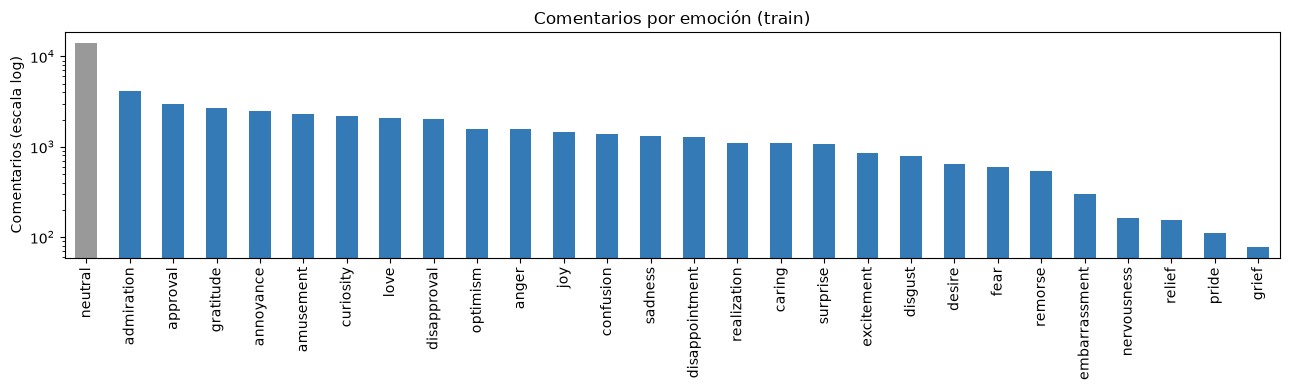

In [6]:
freq = pd.Series(Counter(l for labels in df["emotions"] for l in labels)).sort_values(ascending=False)
pct = (freq / len(df) * 100).round(2)
display(pd.DataFrame({"comentarios": freq, "% del train": pct}).T)

fig, ax = plt.subplots(figsize=(13, 4))
freq.plot(kind="bar", ax=ax, color=["#999999" if l == "neutral" else "#337ab7" for l in freq.index])
ax.set_title("Comentarios por emoción (train)")
ax.set_yscale("log")
ax.set_ylabel("Comentarios (escala log)")
plt.tight_layout()
plt.show()

#### 1.3.3 ¿Cuántas emociones tiene cada comentario? ¿Cuáles aparecen juntas?

n_labels
1    36308
2     6541
3      532
4       28
5        1

16.4% de los comentarios tiene más de una emoción


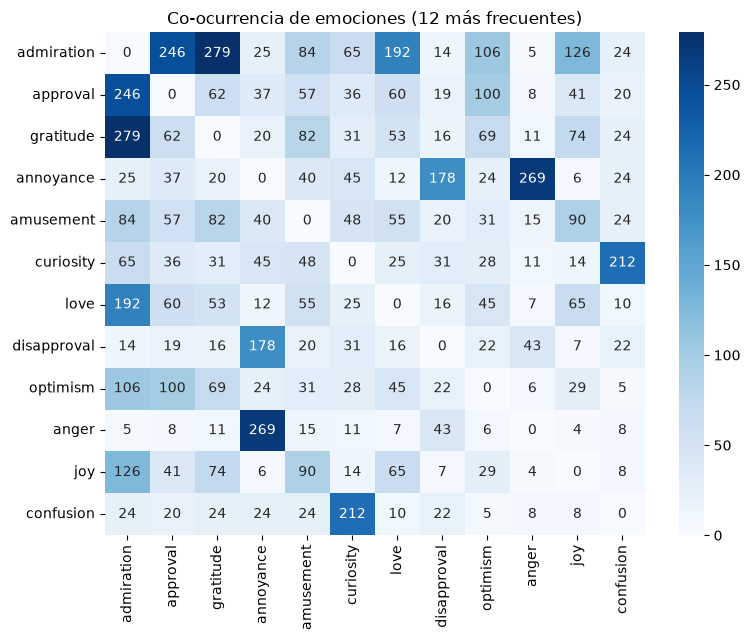

In [7]:
print(df["n_labels"].value_counts().sort_index().rename("comentarios").to_string())
print(f"\n{(df['n_labels'] > 1).mean():.1%} de los comentarios tiene más de una emoción")

multi = df[df["n_labels"] > 1]
top = freq.drop("neutral").head(12).index
co = pd.DataFrame(0, index=top, columns=top)
for labels in multi["emotions"]:
    present = [l for l in labels if l in top]
    for a in present:
        for b in present:
            if a != b:
                co.loc[a, b] += 1

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Co-ocurrencia de emociones (12 más frecuentes)")
plt.tight_layout()
plt.show()

#### 1.3.4 Longitud de los comentarios

Token indices sequence length is longer than the specified maximum sequence length for this model (1437 > 512). Running this sequence through the model will result in indexing errors


       n_words  n_tokens
count  43410.0   43410.0
mean      12.8      18.9
std        6.7      11.0
min        1.0       3.0
25%        7.0      12.0
50%       12.0      18.0
75%       18.0      25.0
max       33.0    1437.0

99.98% de los comentarios caben en MAX_LENGTH=64 tokens


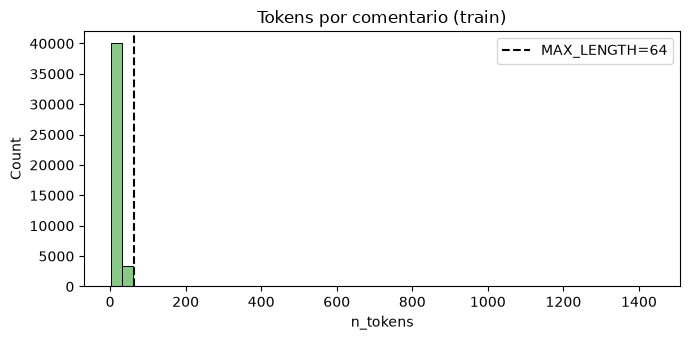

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
df["n_words"] = df["text"].str.split().str.len()
df["n_tokens"] = [len(x) for x in tokenizer(df["text"].tolist())["input_ids"]]
print(df[["n_words", "n_tokens"]].describe().round(1).to_string())
print(f"\n{(df['n_tokens'] <= MAX_LENGTH).mean():.2%} de los comentarios caben en MAX_LENGTH={MAX_LENGTH} tokens")

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df["n_tokens"], bins=50, ax=ax, color="#5cb85c")
ax.axvline(MAX_LENGTH, color="black", linestyle="--", label=f"MAX_LENGTH={MAX_LENGTH}")
ax.set_title("Tokens por comentario (train)")
ax.legend()
plt.tight_layout()
plt.show()

**Hallazgos del EDA**
- El desbalance es extremo: un modelo que siempre responda `neutral` acierta ~1/3 de las veces, pero no sirve.
  Por eso reportamos Macro-F1 además de Micro-F1.
- ~16 % de los comentarios tienen varias emociones, y las combinaciones tienen sentido (*admiration + gratitude*,
  *anger + annoyance*, *joy + love*): el modelo debe poder activar varias salidas a la vez.
- Los comentarios son cortos: con `MAX_LENGTH=64` cabe prácticamente todo, lo que hace el entrenamiento rápido.
- Hay emociones muy parecidas entre sí (*anger/annoyance*, *joy/amusement*, *sadness/disappointment*): incluso los
  anotadores humanos discrepan, lo que pone un techo a cualquier modelo.

### 1.4 Tokenización y preparación de los datos

Convertimos cada lista de emociones en un vector **multi-hot** de 28 posiciones (1.0 si la emoción está presente).
Ese vector es el objetivo de la pérdida *binary cross-entropy*.

In [9]:
def tokenize(batch):
    enc = tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)
    multi_hot = np.zeros((len(batch["labels"]), NUM_LABELS), dtype=np.float32)
    for i, ids in enumerate(batch["labels"]):
        multi_hot[i, ids] = 1.0
    enc["labels"] = multi_hot.tolist()
    return enc

tokenized = raw.map(tokenize, batched=True, remove_columns=raw["train"].column_names)
# La columna original `labels` era de enteros; la pérdida BCE necesita floats.
tokenized = tokenized.cast_column("labels", Sequence(Value("float32")))
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

ex = tokenized["train"][0]
print("Texto:", raw["train"][0]["text"])
print("Tokens:", tokenizer.convert_ids_to_tokens(ex["input_ids"]))
print("Vector multi-hot:", [id2label[i] for i, v in enumerate(ex["labels"]) if v == 1.0])

Texto: My favourite food is anything I didn't have to cook myself.
Tokens: ['<s>', 'My', 'Ġfavourite', 'Ġfood', 'Ġis', 'Ġanything', 'ĠI', 'Ġdidn', "'t", 'Ġhave', 'Ġto', 'Ġcook', 'Ġmyself', '.', '</s>']
Vector multi-hot: ['neutral']


#### Métricas y función de entrenamiento reutilizable

In [10]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def multilabel_metrics(probs, labels, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "exact_match": float((preds == labels).all(axis=1).mean()),
    }


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return multilabel_metrics(sigmoid(logits), labels.astype(int))


def build_trainer(train_ds, eval_ds, learning_rate, batch_size, epochs, output_dir,
                  weight_decay=0.01, save=False, max_steps=-1):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        problem_type="multi_label_classification",  # sigmoide + BCEWithLogitsLoss
    )
    # transformers 5 carga los pesos en el dtype del checkpoint; el fp16 mixto necesita los pesos en fp32.
    model = model.float()
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=128,
        num_train_epochs=epochs,
        max_steps=max_steps,
        weight_decay=weight_decay,
        **WARMUP,
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if save else "no",
        load_best_model_at_end=save,
        metric_for_best_model="micro_f1",
        save_total_limit=1,
        logging_steps=2 if SMOKE else 100,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )


def free_memory(*objects):
    for obj in objects:
        del obj
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### 1.5 Búsqueda de hiperparámetros sobre un *sample*

Comparamos configuraciones con un **sample de 8.000 comentarios** de entrenamiento y **2.000** de validación (2 épocas):
- **Learning rate**: `1e-5`, `2e-5`, `3e-5`, `5e-5`. En multi-etiqueta con clases raras, un learning rate muy bajo
  tiende a dejar al modelo "atascado" prediciendo solo las emociones frecuentes.
- **Batch size**: `16` y `32`.

Elegimos la configuración con mejor **Micro-F1 en validación** y desempatamos mirando el Macro-F1.

In [11]:
if SMOKE:
    N_TRAIN_SAMPLE, N_EVAL_SAMPLE, SEARCH_EPOCHS = 64, 32, 1
    LR_GRID, BS_GRID = [2e-5, 5e-5], [16]
else:
    N_TRAIN_SAMPLE, N_EVAL_SAMPLE, SEARCH_EPOCHS = 8000, 2000, 2
    LR_GRID, BS_GRID = [1e-5, 2e-5, 3e-5, 5e-5], [16, 32]

train_sample = tokenized["train"].shuffle(seed=SEED).select(range(N_TRAIN_SAMPLE))
eval_sample = tokenized["validation"].shuffle(seed=SEED).select(range(N_EVAL_SAMPLE))

results = []
for bs in BS_GRID:
    for lr in LR_GRID:
        start = time.time()
        trainer = build_trainer(train_sample, eval_sample, lr, bs, SEARCH_EPOCHS, f"{OUTPUT_DIR}/search")
        trainer.train()
        metrics = trainer.evaluate()
        elapsed = time.time() - start
        results.append({
            "learning_rate": lr, "batch_size": bs,
            "eval_micro_f1": metrics["eval_micro_f1"], "eval_macro_f1": metrics["eval_macro_f1"],
            "eval_loss": metrics["eval_loss"], "minutes": elapsed / 60,
        })
        print(f"lr={lr:.0e} bs={bs} -> micro-F1={metrics['eval_micro_f1']:.4f} "
              f"macro-F1={metrics['eval_macro_f1']:.4f} ({elapsed/60:.1f} min)")
        free_memory(trainer)

search_df = (pd.DataFrame(results).sort_values(["eval_micro_f1", "eval_macro_f1"], ascending=False)
             .reset_index(drop=True))
os.makedirs(OUTPUT_DIR, exist_ok=True)
search_df.to_csv(f"{OUTPUT_DIR}/hyperparameter_search.csv", index=False)
display(search_df.style.format({"learning_rate": "{:.0e}", "eval_micro_f1": "{:.4f}", "eval_macro_f1": "{:.4f}",
                                "eval_loss": "{:.4f}", "minutes": "{:.1f}"})
        .highlight_max(subset=["eval_micro_f1"], color="#c8e6c9"))

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Exact Match
1,0.158200,0.150451,0.000000,0.000000,0.000000
2,0.142800,0.140777,0.254597,0.045203,0.158000


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


lr=1e-05 bs=16 -> micro-F1=0.2546 macro-F1=0.0452 (0.6 min)


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Exact Match
1,0.145400,0.139543,0.105939,0.025039,0.056500
2,0.128400,0.126396,0.329656,0.055412,0.225500


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (15 outputs left out)

lr=3e-05 bs=32 -> micro-F1=0.2168 macro-F1=0.0195 (0.3 min)


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Exact Match
1,0.151700,0.143540,0.000000,0.000000,0.000000
2,0.136300,0.131642,0.327731,0.053985,0.223500


lr=5e-05 bs=32 -> micro-F1=0.3277 macro-F1=0.0540 (0.3 min)


,learning_rate,batch_size,eval_micro_f1,eval_macro_f1,eval_loss,minutes
0,5e-05,16,0.4292,0.1317,0.1077,0.6
1,3e-05,16,0.3984,0.1101,0.1188,0.6
2,2e-05,16,0.3297,0.0554,0.1264,0.6
3,5e-05,32,0.3277,0.0540,0.1316,0.3
4,1e-05,16,0.2546,0.0452,0.1408,0.6
5,3e-05,32,0.2168,0.0195,0.1389,0.3
6,1e-05,32,0.0000,0.0000,0.1608,0.3
7,2e-05,32,0.0000,0.0000,0.1447,0.3


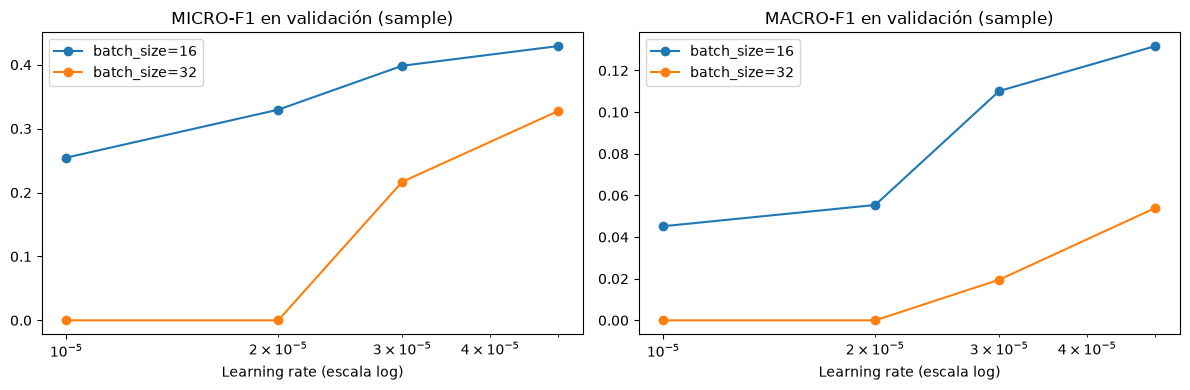

Mejor configuración: learning_rate=5e-05, batch_size=16 (micro-F1=0.4292, macro-F1=0.1317)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in zip(["eval_micro_f1", "eval_macro_f1"], axes):
    for bs, grp in search_df.sort_values("learning_rate").groupby("batch_size"):
        ax.plot(grp["learning_rate"], grp[metric], marker="o", label=f"batch_size={bs}")
    ax.set_xscale("log")
    ax.set_xlabel("Learning rate (escala log)")
    ax.set_title(metric.replace("eval_", "").replace("_", "-").upper() + " en validación (sample)")
    ax.legend()
plt.tight_layout()
plt.show()

best = search_df.iloc[0]
BEST_LR, BEST_BS = float(best["learning_rate"]), int(best["batch_size"])
print(f"Mejor configuración: learning_rate={BEST_LR:.0e}, batch_size={BEST_BS} "
      f"(micro-F1={best['eval_micro_f1']:.4f}, macro-F1={best['eval_macro_f1']:.4f})")

### 1.6 Entrenamiento con la data completa

Entrenamos sobre los **43.410 comentarios** con la mejor configuración durante 4 épocas y guardamos el
*checkpoint* con mejor Micro-F1 en validación (5.426 comentarios). Tiempo aproximado en una T4: ~25 minutos.

In [13]:
FULL_EPOCHS = 4
train_full, eval_full = tokenized["train"], tokenized["validation"]
if SMOKE:
    train_full, eval_full = train_sample, eval_sample

trainer = build_trainer(train_full, eval_full, BEST_LR, BEST_BS, FULL_EPOCHS,
                        f"{OUTPUT_DIR}/checkpoints", save=True, max_steps=10 if SMOKE else -1)
start = time.time()
trainer.train()
print(f"Entrenamiento completo en {(time.time() - start) / 60:.1f} minutos")

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Exact Match
1,0.091900,0.091454,0.537080,0.336662,0.409141
2,0.082800,0.083984,0.570971,0.421573,0.454478
3,0.073300,0.082231,0.587775,0.466810,0.474751
4,0.062700,0.084664,0.588587,0.486532,0.478253


Entrenamiento completo en 6.4 minutos


,epoch,step,eval_loss,eval_micro_f1,eval_macro_f1
0,1.0,2714,0.091454,0.537080,0.336662
1,2.0,5428,0.083984,0.570971,0.421573
2,3.0,8142,0.082231,0.587775,0.466810
3,4.0,10856,0.084664,0.588587,0.486532


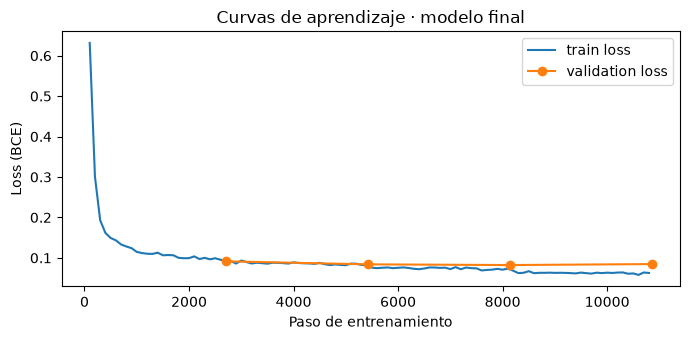

In [14]:
history = pd.DataFrame(trainer.state.log_history)
train_loss = history.dropna(subset=["loss"])[["step", "loss"]]
eval_hist = history.dropna(subset=["eval_loss"])[["epoch", "step", "eval_loss", "eval_micro_f1", "eval_macro_f1"]]
display(eval_hist.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(train_loss["step"], train_loss["loss"], label="train loss")
ax.plot(eval_hist["step"], eval_hist["eval_loss"], marker="o", label="validation loss")
ax.set_xlabel("Paso de entrenamiento")
ax.set_ylabel("Loss (BCE)")
ax.set_title("Curvas de aprendizaje · modelo final")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
BEST_MODEL_DIR = f"{OUTPUT_DIR}/best_model"
trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)
print("Mejor modelo guardado en", BEST_MODEL_DIR)

if PUSH_TO_HUB:
    from huggingface_hub import notebook_login
    notebook_login()
    trainer.model.push_to_hub(HF_REPO_ID)
    tokenizer.push_to_hub(HF_REPO_ID)

Mejor modelo guardado en outputs/goemotions/best_model


### 1.7 Evaluación y demostración del mejor modelo

#### 1.7.1 Ajuste del umbral de decisión (en validación)

El umbral de 0,5 es arbitrario. Como las emociones raras rara vez superan ese valor, probamos umbrales entre 0,05
y 0,9 **sobre validación** (nunca sobre test, para no hacer trampa) y nos quedamos con el que maximiza el Micro-F1.

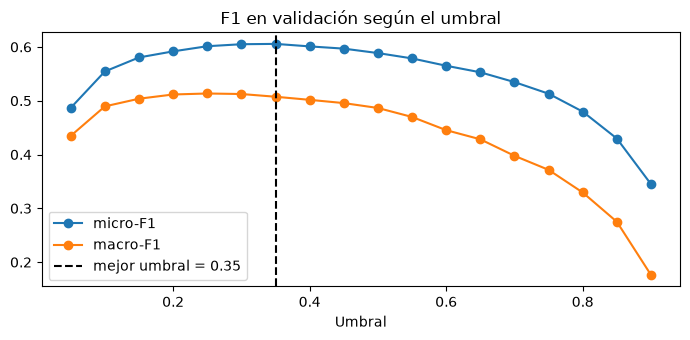

Umbral elegido: 0.35


In [16]:
val_pred = trainer.predict(eval_full)
val_probs, val_labels = sigmoid(val_pred.predictions), val_pred.label_ids.astype(int)
thresholds = np.round(np.arange(0.05, 0.91, 0.05), 2)
th_df = pd.DataFrame([{"threshold": t, **multilabel_metrics(val_probs, val_labels, t)} for t in thresholds])
BEST_THRESHOLD = float(th_df.loc[th_df["micro_f1"].idxmax(), "threshold"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(th_df["threshold"], th_df["micro_f1"], marker="o", label="micro-F1")
ax.plot(th_df["threshold"], th_df["macro_f1"], marker="o", label="macro-F1")
ax.axvline(BEST_THRESHOLD, color="black", linestyle="--", label=f"mejor umbral = {BEST_THRESHOLD}")
ax.set_xlabel("Umbral")
ax.set_title("F1 en validación según el umbral")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Umbral elegido: {BEST_THRESHOLD}")

##### Un umbral por emoción

Un solo umbral para las 28 salidas es un compromiso: las emociones raras (*grief*, *relief*) casi nunca superan valores
altos, mientras que otras (p. ej. *neutral*) acumulan falsos positivos si el umbral es bajo. Elegimos, **para cada emoción**, el umbral
que maximiza su F1 en validación. El test sigue sin tocarse.

Validación · umbral global 0.35: micro-F1=0.6057 macro-F1=0.5074
Validación · umbral por emoción: micro-F1=0.6118 macro-F1=0.5398


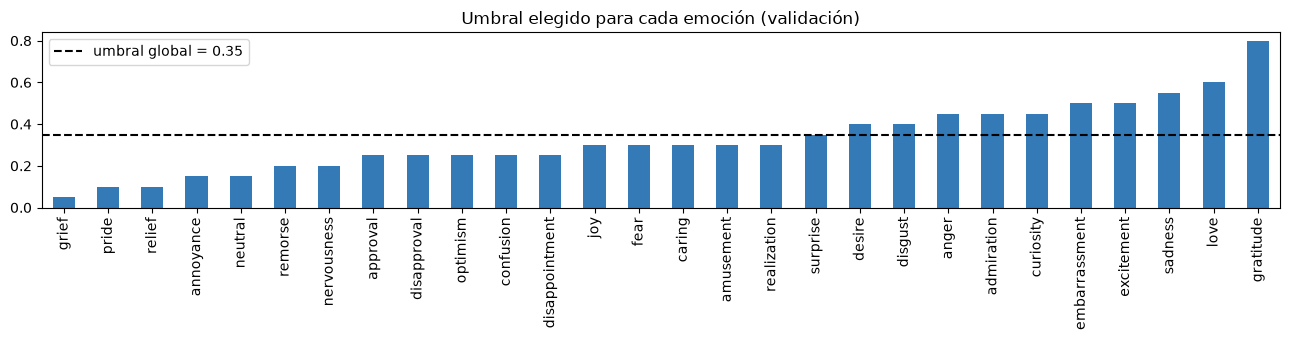

In [17]:
PER_LABEL_THRESHOLDS = np.array([
    max(thresholds, key=lambda t: f1_score(val_labels[:, j], (val_probs[:, j] >= t).astype(int), zero_division=0))
    for j in range(NUM_LABELS)
])
val_global = multilabel_metrics(val_probs, val_labels, BEST_THRESHOLD)
val_per_label = multilabel_metrics(val_probs, val_labels, PER_LABEL_THRESHOLDS)
print(f"Validación · umbral global {BEST_THRESHOLD}: micro-F1={val_global['micro_f1']:.4f} macro-F1={val_global['macro_f1']:.4f}")
print(f"Validación · umbral por emoción: micro-F1={val_per_label['micro_f1']:.4f} macro-F1={val_per_label['macro_f1']:.4f}")

fig, ax = plt.subplots(figsize=(13, 3.5))
pd.Series(PER_LABEL_THRESHOLDS, index=LABEL_NAMES).sort_values().plot(kind="bar", ax=ax, color="#337ab7")
ax.axhline(BEST_THRESHOLD, color="black", linestyle="--", label=f"umbral global = {BEST_THRESHOLD}")
ax.set_title("Umbral elegido para cada emoción (validación)")
ax.legend()
plt.tight_layout()
plt.show()

# Los umbrales son parte del modelo: se guardan junto a los pesos.
import json
with open(f"{BEST_MODEL_DIR}/thresholds.json", "w") as f:
    json.dump(dict(zip(LABEL_NAMES, PER_LABEL_THRESHOLDS.round(2).tolist())), f, indent=2)

#### 1.7.2 Línea base clásica: TF-IDF + regresión logística

Para saber cuánto aporta el Transformer, entrenamos un modelo clásico sin GPU: cada comentario se representa con
**TF-IDF** de palabras y bigramas, y se entrena **una regresión logística por emoción** (*one-vs-rest*). Este modelo
solo ve qué palabras aparecen, no su orden ni su contexto. Su umbral también se ajusta en validación, para que la
comparación sea justa.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier


def multi_hot(label_lists):
    y = np.zeros((len(label_lists), NUM_LABELS), dtype=int)
    for i, ids in enumerate(label_lists):
        y[i, ids] = 1
    return y


base_train = raw["train"].select(range(2000)) if SMOKE else raw["train"]
base_val = raw["validation"].select(range(N_EVAL_SAMPLE)) if SMOKE else raw["validation"]
base_test = raw["test"].select(range(200)) if SMOKE else raw["test"]

start = time.time()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)
X_train = vectorizer.fit_transform(base_train["text"])
tfidf_clf = OneVsRestClassifier(LogisticRegression(C=4.0, max_iter=1000), n_jobs=-1)
tfidf_clf.fit(X_train, multi_hot(base_train["labels"]))
print(f"TF-IDF + LR entrenado en {time.time() - start:.1f} s ({X_train.shape[1]} features)")

val_probs_tfidf = tfidf_clf.predict_proba(vectorizer.transform(base_val["text"]))
val_labels_tfidf = multi_hot(base_val["labels"])
TFIDF_THRESHOLD = float(max(thresholds, key=lambda t: multilabel_metrics(val_probs_tfidf, val_labels_tfidf, t)["micro_f1"]))
test_probs_tfidf = tfidf_clf.predict_proba(vectorizer.transform(base_test["text"]))
print(f"Umbral elegido para TF-IDF + LR (validación): {TFIDF_THRESHOLD}")

TF-IDF + LR entrenado en 5.2 s (50000 features)


Umbral elegido para TF-IDF + LR (validación): 0.2


#### 1.7.3 Métricas sobre el conjunto de prueba (5.427 comentarios nunca vistos)

In [19]:
test_ds = tokenized["test"].select(range(200)) if SMOKE else tokenized["test"]
test_pred = trainer.predict(test_ds)
test_probs, test_labels = sigmoid(test_pred.predictions), test_pred.label_ids.astype(int)

baseline_preds = np.zeros_like(test_labels)
baseline_preds[:, label2id["neutral"]] = 1  # línea base: "todo es neutral"
summary = pd.DataFrame([
    {"modelo": "Línea base: siempre 'neutral'", **multilabel_metrics(baseline_preds.astype(float), test_labels)},
    {"modelo": f"Línea base clásica: TF-IDF + regresión logística · umbral {TFIDF_THRESHOLD}",
     **multilabel_metrics(test_probs_tfidf, test_labels, TFIDF_THRESHOLD)},
    {"modelo": f"{MODEL_NAME} fine-tuned · umbral 0.5", **multilabel_metrics(test_probs, test_labels, 0.5)},
    {"modelo": f"{MODEL_NAME} fine-tuned · umbral global {BEST_THRESHOLD}",
     **multilabel_metrics(test_probs, test_labels, BEST_THRESHOLD)},
    {"modelo": f"{MODEL_NAME} fine-tuned · umbral por emoción",
     **multilabel_metrics(test_probs, test_labels, PER_LABEL_THRESHOLDS)},
]).set_index("modelo")
display(summary.round(4))

,micro_f1,macro_f1,exact_match
modelo,,,
Línea base: siempre 'neutral',0.3040,0.0177,0.2959
Línea base clásica: TF-IDF + regresión logística · umbral 0.2,0.5540,0.4200,0.3790
FacebookAI/roberta-base fine-tuned · umbral 0.5,0.5939,0.4827,0.4830
FacebookAI/roberta-base fine-tuned · umbral global 0.35,0.6050,0.5093,0.4671
FacebookAI/roberta-base fine-tuned · umbral por emoción,0.6034,0.5229,0.4081


#### 1.7.4 Desempeño por emoción

Comparamos el F1 de cada emoción entre el Transformer y la línea base TF-IDF.

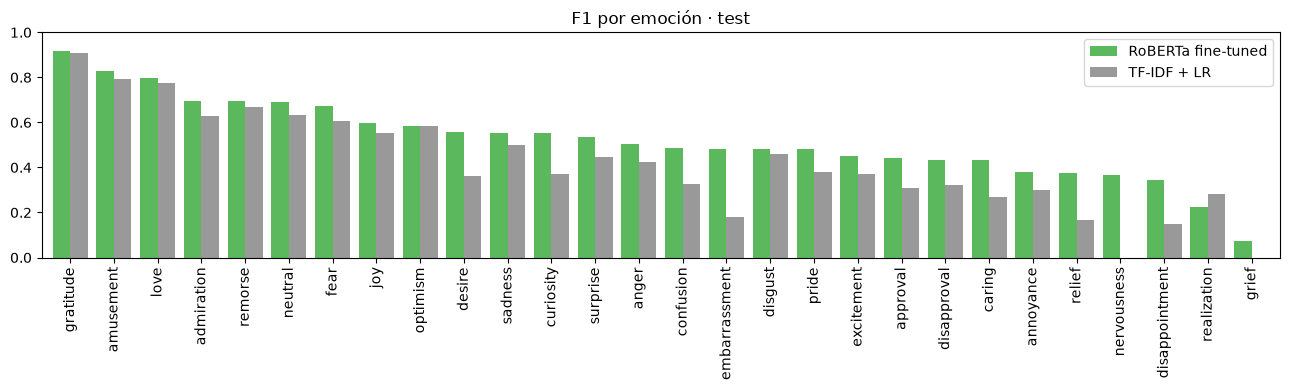

,precision,recall,f1-score,f1 TF-IDF,support
gratitude,0.971,0.866,0.916,0.909,352.0
amusement,0.748,0.924,0.827,0.793,264.0
love,0.796,0.803,0.799,0.773,238.0
admiration,0.670,0.726,0.697,0.628,504.0
remorse,0.553,0.929,0.693,0.667,56.0
neutral,0.583,0.844,0.689,0.631,1787.0
fear,0.600,0.769,0.674,0.608,78.0
joy,0.546,0.665,0.599,0.551,161.0
optimism,0.552,0.624,0.586,0.584,186.0
desire,0.717,0.458,0.559,0.361,83.0


In [20]:
test_preds = (test_probs >= PER_LABEL_THRESHOLDS).astype(int)
report = pd.DataFrame(classification_report(test_labels, test_preds, target_names=LABEL_NAMES,
                                            output_dict=True, zero_division=0)).T
per_class = report.loc[LABEL_NAMES].sort_values("f1-score", ascending=False)
tfidf_report = pd.DataFrame(classification_report(test_labels, (test_probs_tfidf >= TFIDF_THRESHOLD).astype(int),
                                                  target_names=LABEL_NAMES, output_dict=True, zero_division=0)).T
per_class["f1 TF-IDF"] = tfidf_report.loc[per_class.index, "f1-score"]

fig, ax = plt.subplots(figsize=(13, 4))
per_class[["f1-score", "f1 TF-IDF"]].rename(columns={"f1-score": "RoBERTa fine-tuned", "f1 TF-IDF": "TF-IDF + LR"}).plot(
    kind="bar", ax=ax, color=["#5cb85c", "#999999"], width=0.8)
ax.set_title("F1 por emoción · test")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()
display(per_class[["precision", "recall", "f1-score", "f1 TF-IDF", "support"]].round(3))

#### 1.7.5 Probando el modelo con comentarios nuevos

In [21]:
model = trainer.model.eval()

def predict_emotions(texts, thresholds=PER_LABEL_THRESHOLDS, top_k=3):
    enc = tokenizer(texts, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = torch.sigmoid(model(**enc).logits).float().cpu().numpy()
    for text, p in zip(texts, probs):
        order = np.argsort(-p)
        detected = [f"{id2label[i]} ({p[i]:.2f})" for i in order if p[i] >= thresholds[i]] or ["(ninguna sobre el umbral)"]
        top = ", ".join(f"{id2label[i]} {p[i]:.2f}" for i in order[:top_k])
        print(f"{text}\n   -> detectadas: {', '.join(detected)}   | top-{top_k}: {top}\n")

predict_emotions([
    "Thank you so much for helping me with my thesis, you are amazing!",
    "I can't believe they cancelled the show after that cliffhanger. Unbelievable.",
    "Wait, so the exam is tomorrow?? I thought it was next week...",
    "My dog passed away this morning. I miss him already.",
    "Finally got the job offer!!! I'm so relieved and excited.",
])

Thank you so much for helping me with my thesis, you are amazing!
   -> detectadas: gratitude (0.98), admiration (0.75)   | top-3: gratitude 0.98, admiration 0.75, joy 0.01

I can't believe they cancelled the show after that cliffhanger. Unbelievable.
   -> detectadas: surprise (0.89)   | top-3: surprise 0.89, neutral 0.06, disappointment 0.03

Wait, so the exam is tomorrow?? I thought it was next week...
   -> detectadas: curiosity (0.51), confusion (0.30), neutral (0.28)   | top-3: curiosity 0.51, confusion 0.30, neutral 0.28

My dog passed away this morning. I miss him already.
   -> detectadas: sadness (0.95), grief (0.07)   | top-3: sadness 0.95, disappointment 0.07, grief 0.07

Finally got the job offer!!! I'm so relieved and excited.
   -> detectadas: excitement (0.89)   | top-3: excitement 0.89, joy 0.30, gratitude 0.05



### 1.8 Conclusiones

- Pasar de clasificación binaria a **multi-etiqueta** cambia tres cosas: la representación de la salida (vector
  multi-hot), la función de activación/pérdida (sigmoide + BCE) y la decisión final (un **umbral**, que conviene ajustar en validación).
- El modelo *fine-tuned* supera a la línea base trivial "siempre neutral" y también a un modelo clásico TF-IDF +
  regresión logística (sección 1.7.3): entender el contexto y no solo las palabras sueltas marca la diferencia, sobre
  todo en emociones expresadas sin vocabulario explícito (sección 1.7.4). Además, bajar el umbral
  ayuda a recuperar emociones menos frecuentes.
- Las emociones con vocabulario explícito (*gratitude*: "thanks"; *love*; *amusement*: "lol") se detectan muy bien;
  las sutiles o raras (*grief*, *relief*, *nervousness*, *realization*) son las más difíciles, por falta de ejemplos
  y porque incluso los anotadores discrepan.
- El **learning rate** fue el hiperparámetro más sensible en la búsqueda (sección 1.5).
- Posibles mejoras: pérdidas que compensen el desbalance (*focal loss*, pesos por clase) o agrupar emociones en las 6 categorías de Ekman para aplicaciones que no requieren tanto detalle.

### 1.9 Resultados de la parte 1 y liberación de memoria

Guardamos las métricas finales para el resumen de la sección 4 y liberamos la memoria de la GPU antes de la siguiente parte.

In [22]:
_tfidf_row = [i for i in summary.index if "TF-IDF" in i][0]
FINAL_RESULTS += [
    {"Parte": "1. Emociones", "Modelo": MODEL_NAME, "Métrica (test)": "Micro-F1",
     "Línea base clásica": summary.loc[_tfidf_row, "micro_f1"], "Modelo fine-tuned": summary.iloc[-1]["micro_f1"]},
    {"Parte": "1. Emociones", "Modelo": MODEL_NAME, "Métrica (test)": "Macro-F1",
     "Línea base clásica": summary.loc[_tfidf_row, "macro_f1"], "Modelo fine-tuned": summary.iloc[-1]["macro_f1"]},
]

for _name in ["trainer", "model", "tokenized", "prepared", "tokd", "train_sample", "eval_sample", "train_full",
              "eval_full", "tfidf_clf", "X_train", "extractor", "toxicity", "pred", "val_pred", "test_pred"]:
    globals().pop(_name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memoria de GPU en uso tras limpiar: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
display(pd.DataFrame(FINAL_RESULTS[-2:]).set_index("Parte").round(3))

Memoria de GPU en uso tras limpiar: 0.02 GB


,Modelo,Métrica (test),Línea base clásica,Modelo fine-tuned
Parte,,,,
1. Emociones,FacebookAI/roberta-base,Micro-F1,0.554,0.603
1. Emociones,FacebookAI/roberta-base,Macro-F1,0.420,0.523


## Parte 2 · Etiquetado de secuencias. Extracción de habilidades en ofertas de empleo

**Problema:** leer una oferta de trabajo en inglés y marcar, **palabra por palabra**, qué fragmentos son
**habilidades** (*skills*: "work in a team", "manage stakeholders") y cuáles son **conocimientos**
(*knowledge*: "Python", "Kubernetes", "nursing degree").

**Dataset:** [SkillSpan](https://huggingface.co/datasets/jjzha/skillspan) (Zhang et al., NAACL 2022).
**Modelos comparados:** [`bert-base-cased`](https://huggingface.co/bert-base-cased) (BERT genérico),
[`jjzha/jobbert-base-cased`](https://huggingface.co/jjzha/jobbert-base-cased), un BERT que siguió su
pre-entrenamiento con ~3,2 millones de oraciones de ofertas de empleo, y
[`microsoft/deberta-v3-base`](https://huggingface.co/microsoft/deberta-v3-base), un encoder más moderno del mismo
tamaño. ¿Gana el modelo del dominio o la arquitectura más reciente?


### 2.1 Configuración e importaciones

Cada parte importa lo que usa, para que se pueda volver a ejecutar desde aquí sin depender de las otras.

In [23]:
import gc
import os
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    Trainer,
    TrainingArguments,
    pipeline,
    set_seed,
)

SMOKE = os.environ.get("SMOKE", "0") == "1"  # True = corrida rápida de verificación
SEED = 42
CANDIDATE_MODELS = ["bert-base-cased", "jjzha/jobbert-base-cased", "microsoft/deberta-v3-base"]
OUTPUT_DIR = "outputs/skillspan"
PUSH_TO_HUB = False
HF_USER = "jeffespejo"  # el nombre del repo se arma con el modelo ganador (sección 2.6)

set_seed(SEED)
# transformers 5 eliminó `warmup_ratio`; ahora `warmup_steps` acepta una fracción de los pasos totales.
import inspect
WARMUP = ({"warmup_ratio": 0.1} if "warmup_ratio" in inspect.signature(TrainingArguments).parameters
          else {"warmup_steps": 0.1})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()
print(f"Dispositivo: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"SMOKE = {SMOKE}")

Dispositivo: cuda (NVIDIA GeForce RTX 5070 Ti)
SMOKE = False


### 2.2 Descripción de la base de datos

| Aspecto | Descripción |
|---|---|
| **Dominio** | Ofertas de empleo reales en inglés, de dos fuentes: **tech** (StackOverflow Jobs, puestos de tecnología) y **house** (un portal de empleo con perfiles variados: salud, ventas, logística…). Los datos personales están anonimizados (`<ORGANIZATION>`, `<ADDRESS>`, `<LOCATION>`). |
| **Tipo de problema** | Etiquetado de secuencias (*token classification*), esquema **BIO**. |
| **Entrada (X)** | `tokens`: una oración de la oferta, ya separada en palabras. |
| **Salida (y)** | Dos capas de etiquetas por palabra: `tags_skill` y `tags_knowledge`, cada una con `B` (inicio), `I` (dentro) u `O` (fuera). |
| **Tamaño** | 4.800 oraciones de entrenamiento, 3.174 de validación y 3.569 de prueba (~265 ofertas completas). |
| **Anotación** | Expertos anotaron siguiendo la taxonomía europea ESCO. |

**Habilidad vs. conocimiento (según ESCO).** Una **habilidad** es la capacidad de *aplicar* algo para hacer una tarea
(suele empezar con un verbo: *"communicate with clients"*, *"lead a team"*). Un **conocimiento** es algo que se
*sabe* (suele ser un sustantivo: *"Java"*, *"agile methodologies"*, *"pharmacology"*).

**Utilidad.** Extraer habilidades automáticamente es la base de los sistemas de reclutamiento: emparejar CVs con
ofertas, analizar qué habilidades pide el mercado laboral, detectar brechas de formación y recomendar cursos.

**Métrica.** **F1 a nivel de span** (`seqeval`): un fragmento cuenta como acierto solo si el tipo **y** los límites
coinciden exactamente. Es exigente: las habilidades son frases largas y difusas, por eso los F1 de este dataset
son bastante más bajos que en NER clásico (en el paper, alrededor de 0,6).

In [24]:
raw = load_dataset("jjzha/skillspan")
for name, ds in raw.items():
    print(f"{name:>10}: {len(ds):>6} oraciones")
print("Columnas:", raw["train"].column_names)

     train:   4800 oraciones
validation:   3174 oraciones
      test:   3569 oraciones
Columnas: ['idx', 'tokens', 'tags_skill', 'tags_knowledge', 'source']


### 2.3 Análisis exploratorio (EDA)

#### 2.3.1 Algunos ejemplos, palabra por palabra

In [25]:
def has_spans(ex):
    return any(t != "O" for t in ex["tags_skill"] + ex["tags_knowledge"])

def show_sentence(ex):
    return pd.DataFrame({"token": ex["tokens"], "skill": ex["tags_skill"], "knowledge": ex["tags_knowledge"]}).T

annotated = [i for i, ex in enumerate(raw["train"].select(range(300))) if has_spans(ex)]
for idx in annotated[:3]:
    ex = raw["train"][idx]
    print(f"[{ex['source']}] " + " ".join(ex["tokens"]))
    display(show_sentence(ex))

[tech] Business to Business Information Technology Web Technology


,0,1,2,3,4,5,6
token,Business,to,Business,Information,Technology,Web,Technology
skill,O,O,O,O,O,O,O
knowledge,B,I,I,B,I,B,I


[tech] docker agile selenium circleci jenkins


,0,1,2,3,4
token,docker,agile,selenium,circleci,jenkins
skill,O,O,O,O,O
knowledge,B,B,B,B,B


[tech] You will be working in an end-to-end cross-functional team being responsible for implementing and promoting all QA relevant topics on team level .


,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
token,You,will,be,working,in,an,end-to-end,cross-functional,team,being,...,and,promoting,all,QA,relevant,topics,on,team,level,.
skill,O,O,O,O,O,O,O,O,O,O,...,I,I,I,I,I,I,O,O,O,O
knowledge,O,O,O,O,O,O,O,O,O,O,...,O,O,O,B,O,O,O,O,O,O


#### 2.3.2 ¿Cuántas oraciones tienen habilidades o conocimientos?

In [26]:
def extract_spans(tokens, tags):
    spans, current = [], []
    for tok, tag in zip(tokens + ["<END>"], tags + ["O"]):
        if tag == "I" and current:
            current.append(tok)
            continue
        if current:
            spans.append(" ".join(current))
            current = []
        if tag in ("B", "I"):
            current = [tok]
    return spans

rows = []
for name, ds in raw.items():
    for ex in ds:
        rows.append({
            "split": name, "source": ex["source"], "n_tokens": len(ex["tokens"]),
            "skills": extract_spans(ex["tokens"], ex["tags_skill"]),
            "knowledge": extract_spans(ex["tokens"], ex["tags_knowledge"]),
        })
eda = pd.DataFrame(rows)
eda["n_skills"], eda["n_knowledge"] = eda["skills"].str.len(), eda["knowledge"].str.len()
eda["any_span"] = (eda["n_skills"] + eda["n_knowledge"]) > 0

display(eda.groupby("split")[["n_skills", "n_knowledge"]].sum().rename(columns={"n_skills": "skills", "n_knowledge": "knowledge"}))
display(eda.groupby(["split", "source"])["any_span"].mean().unstack().round(3).rename_axis(columns="% oraciones con spans"))

,skills,knowledge
split,,
test,1091,1174
train,2221,2969
validation,1070,1093


% oraciones con spans,house,tech
split,,
test,0.328,0.242
train,0.337,0.326
validation,0.343,0.262


#### 2.3.3 Longitud de los spans y spans más frecuentes

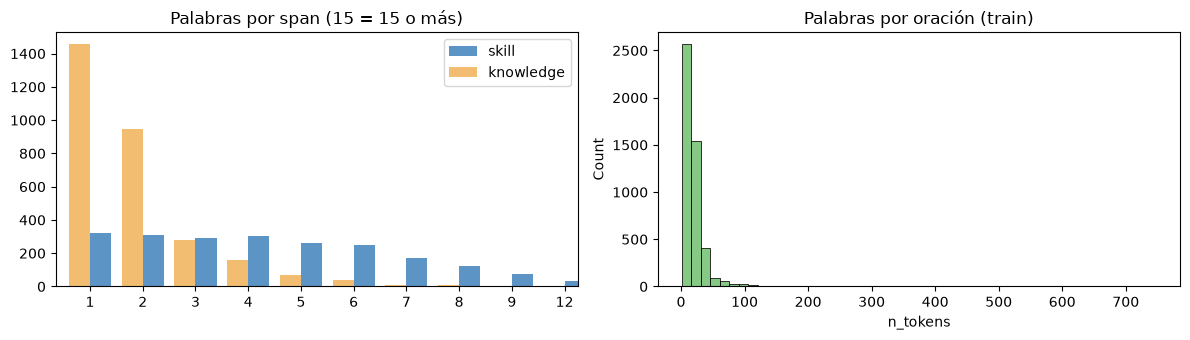

Skill: 4.5 palabras en promedio | Knowledge: 1.9


,knowledge más frecuente,skill más frecuente
0,English (53),communication skills (25)
1,Python (23),motivated (12)
2,Financial Services (21),passionate (10)
3,Java (20),proactive (9)
4,JavaScript (20),team player (9)
5,Kubernetes (20),communication (8)
6,cloud (15),analytical (8)
7,AWS (15),apply your depth of knowledge and expertise (7)
8,Docker (14),partner continuously with your many stakeholders (7)
9,amazon-web-services (14),curious (7)


In [27]:
train_eda = eda[eda["split"] == "train"]
skill_spans = [s for spans in train_eda["skills"] for s in spans]
know_spans = [s for spans in train_eda["knowledge"] for s in spans]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
pd.Series([len(s.split()) for s in skill_spans]).clip(upper=15).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="#337ab7", alpha=0.8, position=0, width=0.4, label="skill")
pd.Series([len(s.split()) for s in know_spans]).clip(upper=15).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="#f0ad4e", alpha=0.8, position=1, width=0.4, label="knowledge")
axes[0].set_title("Palabras por span (15 = 15 o más)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=0)
sns.histplot(train_eda["n_tokens"], bins=50, ax=axes[1], color="#5cb85c")
axes[1].set_title("Palabras por oración (train)")
plt.tight_layout()
plt.show()

print(f"Skill: {np.mean([len(s.split()) for s in skill_spans]):.1f} palabras en promedio | "
      f"Knowledge: {np.mean([len(s.split()) for s in know_spans]):.1f}")
display(pd.DataFrame({
    "knowledge más frecuente": [f"{s} ({c})" for s, c in Counter(know_spans).most_common(12)],
    "skill más frecuente": [f"{s} ({c})" for s, c in Counter(skill_spans).most_common(12)],
}))

**Hallazgos del EDA**
- Solo entre ~1/4 y ~1/3 de las oraciones contiene algún span: muchas oraciones son títulos, datos de contacto o beneficios.
  El modelo debe aprender también a **no** marcar nada.
- Las **habilidades** son frases largas (≈4,5 palabras en promedio, a veces más de 10), mientras que los **conocimientos** son
  cortos (≈1,9 palabras, típicamente nombres de tecnologías). Por eso esperamos un F1 más bajo en *skill*.
- Las ofertas de tecnología (`tech`) son ricas en conocimientos (lenguajes, herramientas); las de `house` tienen
  más habilidades blandas y de servicio.
- Hay vocabulario muy específico del dominio laboral, lo que motiva comparar BERT genérico con **JobBERT**
  (pre-entrenado en ofertas de empleo) y con **DeBERTa-v3** (arquitectura más reciente).

### 2.4 Unificación de etiquetas, tokenización y alineación

#### 2.4.1 De dos capas a una sola secuencia de etiquetas

Unimos las dos capas en un único esquema de 5 etiquetas: `O`, `B-SKILL`, `I-SKILL`, `B-KNOWLEDGE`, `I-KNOWLEDGE`.
En los pocos tokens marcados en ambas capas (~3 % de los tokens de *skill*, normalmente un conocimiento dentro de una
habilidad, p. ej. *"develop software in **Python**"*) le damos prioridad a la habilidad, que es el span más largo.

In [28]:
LABEL_NAMES = ["O", "B-SKILL", "I-SKILL", "B-KNOWLEDGE", "I-KNOWLEDGE"]
id2label = dict(enumerate(LABEL_NAMES))
label2id = {v: k for k, v in id2label.items()}

def merge_tags(batch):
    merged = []
    for skill, know in zip(batch["tags_skill"], batch["tags_knowledge"]):
        tags = []
        for s, k in zip(skill, know):
            if s != "O":
                tags.append(label2id[f"{s}-SKILL"])
            elif k != "O":
                tags.append(label2id[f"{k}-KNOWLEDGE"])
            else:
                tags.append(label2id["O"])
        merged.append(tags)
    return {"ner_tags": merged}

dataset = raw.map(merge_tags, batched=True)
overlap = sum(s != "O" and k != "O" for ex in raw["train"] for s, k in zip(ex["tags_skill"], ex["tags_knowledge"]))
print(f"Tokens con ambas etiquetas en train: {overlap}")
print(list(zip(dataset["train"][annotated[0]]["tokens"], [id2label[t] for t in dataset["train"][annotated[0]]["ner_tags"]])))

Tokens con ambas etiquetas en train: 347
[('Business', 'B-KNOWLEDGE'), ('to', 'I-KNOWLEDGE'), ('Business', 'I-KNOWLEDGE'), ('Information', 'B-KNOWLEDGE'), ('Technology', 'I-KNOWLEDGE'), ('Web', 'B-KNOWLEDGE'), ('Technology', 'I-KNOWLEDGE')]


#### 2.4.2 Tokenización por sub-palabras y alineación de etiquetas

BERT divide palabras poco frecuentes en sub-palabras (`"Kubernetes"` → `"Ku", "##ber", "##net", "##es"`).
El **primer** sub-token de cada palabra recibe su etiqueta, y los siguientes y los tokens especiales reciben
`-100` (la pérdida los ignora). Como comparamos tres modelos, tokenizamos el dataset con el tokenizador de cada uno.

In [29]:
def make_tokenized(model_name):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def tokenize_and_align(batch):
        enc = tokenizer(batch["tokens"], truncation=True, max_length=256, is_split_into_words=True)
        all_labels = []
        for i, tags in enumerate(batch["ner_tags"]):
            labels, previous = [], None
            for word_id in enc.word_ids(batch_index=i):
                labels.append(-100 if word_id is None or word_id == previous else tags[word_id])
                previous = word_id
            all_labels.append(labels)
        enc["labels"] = all_labels
        return enc

    cols = dataset["train"].column_names
    return tokenizer, dataset.map(tokenize_and_align, batched=True, remove_columns=cols)

prepared = {name: make_tokenized(name) for name in CANDIDATE_MODELS}

tok, tokd = prepared["bert-base-cased"]
ex = tokd["train"][annotated[0]]
display(pd.DataFrame({"sub-token": tok.convert_ids_to_tokens(ex["input_ids"]),
                      "label": [id2label.get(l, "-100") for l in ex["labels"]]}).T)

,0,1,2,3,4,5,6,7,8
sub-token,[CLS],Business,to,Business,Information,Technology,Web,Technology,[SEP]
label,-100,B-KNOWLEDGE,I-KNOWLEDGE,I-KNOWLEDGE,B-KNOWLEDGE,I-KNOWLEDGE,B-KNOWLEDGE,I-KNOWLEDGE,-100


#### Métricas y función de entrenamiento reutilizable

In [30]:
def to_tag_sequences(predictions, labels):
    preds = np.argmax(predictions, axis=-1)
    true_tags, pred_tags = [], []
    for p_row, l_row in zip(preds, labels):
        keep = l_row != -100
        true_tags.append([id2label[l] for l in l_row[keep]])
        pred_tags.append([id2label[p] for p in p_row[keep]])
    return true_tags, pred_tags


def compute_metrics(eval_pred):
    true_tags, pred_tags = to_tag_sequences(*eval_pred)
    report = classification_report(true_tags, pred_tags, output_dict=True, zero_division=0)
    return {
        "precision": precision_score(true_tags, pred_tags, zero_division=0),
        "recall": recall_score(true_tags, pred_tags, zero_division=0),
        "f1": f1_score(true_tags, pred_tags, zero_division=0),
        "f1_skill": report.get("SKILL", {}).get("f1-score", 0.0),
        "f1_knowledge": report.get("KNOWLEDGE", {}).get("f1-score", 0.0),
    }


def build_trainer(model_name, train_ds, eval_ds, learning_rate, batch_size, epochs, output_dir,
                  save=False, max_steps=-1):
    tokenizer = prepared[model_name][0]
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id
    )
    # transformers 5 carga los pesos en el dtype del checkpoint (DeBERTa-v3 viene en fp16); el fp16 mixto necesita fp32.
    model = model.float()
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        max_steps=max_steps,
        weight_decay=0.01,
        **WARMUP,
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if save else "no",
        load_best_model_at_end=save,
        metric_for_best_model="f1",
        save_total_limit=1,
        logging_steps=2 if SMOKE else 50,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,
        data_collator=DataCollatorForTokenClassification(tokenizer=tokenizer),
        compute_metrics=compute_metrics,
    )


def free_memory(*objects):
    for obj in objects:
        del obj
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### 2.5 Búsqueda de hiperparámetros: modelo × learning rate

Además del **learning rate** (`1e-5`, `2e-5`, `3e-5`, `5e-5`), tratamos el **modelo pre-entrenado** como un
hiperparámetro: BERT genérico vs. JobBERT vs. DeBERTa-v3. Usamos un *sample* de **2.500 oraciones** de entrenamiento y
**1.000** de validación, 4 épocas, batch size 16 (el dataset es pequeño, así que batches pequeños dan más
actualizaciones por época). Elegimos la combinación con mejor **F1 por span** en validación.

In [31]:
if SMOKE:
    N_TRAIN_SAMPLE, N_EVAL_SAMPLE, SEARCH_EPOCHS, BATCH_SIZE = 64, 32, 1, 16
    LR_GRID = [3e-5, 5e-5]
else:
    N_TRAIN_SAMPLE, N_EVAL_SAMPLE, SEARCH_EPOCHS, BATCH_SIZE = 2500, 1000, 4, 16
    LR_GRID = [1e-5, 2e-5, 3e-5, 5e-5]

results = []
for model_name in CANDIDATE_MODELS:
    tokd = prepared[model_name][1]
    train_sample = tokd["train"].shuffle(seed=SEED).select(range(N_TRAIN_SAMPLE))
    eval_sample = tokd["validation"].shuffle(seed=SEED).select(range(N_EVAL_SAMPLE))
    for lr in LR_GRID:
        start = time.time()
        trainer = build_trainer(model_name, train_sample, eval_sample, lr, BATCH_SIZE, SEARCH_EPOCHS,
                                f"{OUTPUT_DIR}/search")
        trainer.train()
        metrics = trainer.evaluate()
        elapsed = time.time() - start
        results.append({
            "model": model_name, "learning_rate": lr,
            "eval_f1": metrics["eval_f1"], "eval_f1_skill": metrics["eval_f1_skill"],
            "eval_f1_knowledge": metrics["eval_f1_knowledge"], "eval_loss": metrics["eval_loss"],
            "minutes": elapsed / 60,
        })
        print(f"{model_name:<26} lr={lr:.0e} -> F1={metrics['eval_f1']:.4f} "
              f"(skill {metrics['eval_f1_skill']:.3f}, knowledge {metrics['eval_f1_knowledge']:.3f}) [{elapsed/60:.1f} min]")
        free_memory(trainer)

search_df = pd.DataFrame(results).sort_values("eval_f1", ascending=False).reset_index(drop=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
search_df.to_csv(f"{OUTPUT_DIR}/hyperparameter_search.csv", index=False)
display(search_df.style.format({"learning_rate": "{:.0e}", "eval_f1": "{:.4f}", "eval_f1_skill": "{:.4f}",
                                "eval_f1_knowledge": "{:.4f}", "eval_loss": "{:.4f}", "minutes": "{:.1f}"})
        .highlight_max(subset=["eval_f1"], color="#c8e6c9"))

Some weights of BertForTokenClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,F1 Skill,F1 Knowledge
1,0.428900,0.399440,0.244224,0.214493,0.228395,0.070234,0.363897
2,0.302600,0.328342,0.355844,0.397101,0.375342,0.238849,0.499346
3,0.193000,0.304496,0.383394,0.455072,0.416170,0.302632,0.531375
4,0.175700,0.312971,0.373832,0.463768,0.413972,0.304233,0.518987


Some weights of BertForTokenClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


bert-base-cased            lr=1e-05 -> F1=0.4140 (skill 0.304, knowledge 0.519) [0.5 min]


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,F1 Skill,F1 Knowledge
1,0.338100,0.331374,0.333801,0.344928,0.339273,0.191860,0.481119
2,0.233100,0.296798,0.410026,0.462319,0.434605,0.319648,0.534351
3,0.129400,0.303069,0.436518,0.523188,0.475939,0.393981,0.552163
4,0.098600,0.326312,0.447433,0.530435,0.485411,0.413408,0.550505


Some weights of BertForTokenClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (31 outputs left out)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,F1 Skill,F1 Knowledge
1,0.284200,0.260039,0.426488,0.508696,0.463979,0.406210,0.524324
2,0.176300,0.292810,0.543056,0.566667,0.554610,0.462935,0.635514
3,0.090900,0.262174,0.530321,0.646377,0.582626,0.505405,0.654867
4,0.052300,0.300333,0.556663,0.647826,0.598794,0.522346,0.669241


microsoft/deberta-v3-base  lr=5e-05 -> F1=0.5988 (skill 0.522, knowledge 0.669) [0.8 min]


,model,learning_rate,eval_f1,eval_f1_skill,eval_f1_knowledge,eval_loss,minutes
0,microsoft/deberta-v3-base,5e-05,0.5988,0.5223,0.6692,0.3003,0.8
1,microsoft/deberta-v3-base,3e-05,0.5846,0.5137,0.6506,0.2755,0.8
2,microsoft/deberta-v3-base,2e-05,0.5712,0.4918,0.6447,0.2695,0.8
3,jjzha/jobbert-base-cased,5e-05,0.5288,0.4681,0.5845,0.3115,0.5
4,jjzha/jobbert-base-cased,3e-05,0.5046,0.4228,0.5821,0.2952,0.4
5,bert-base-cased,5e-05,0.5040,0.4514,0.5510,0.3768,0.5
6,bert-base-cased,3e-05,0.4963,0.4340,0.5522,0.3454,0.4
7,microsoft/deberta-v3-base,1e-05,0.4954,0.3825,0.5980,0.2722,0.8
8,jjzha/jobbert-base-cased,2e-05,0.4934,0.4071,0.5736,0.2863,0.5
9,bert-base-cased,2e-05,0.4854,0.4134,0.5505,0.3263,0.5


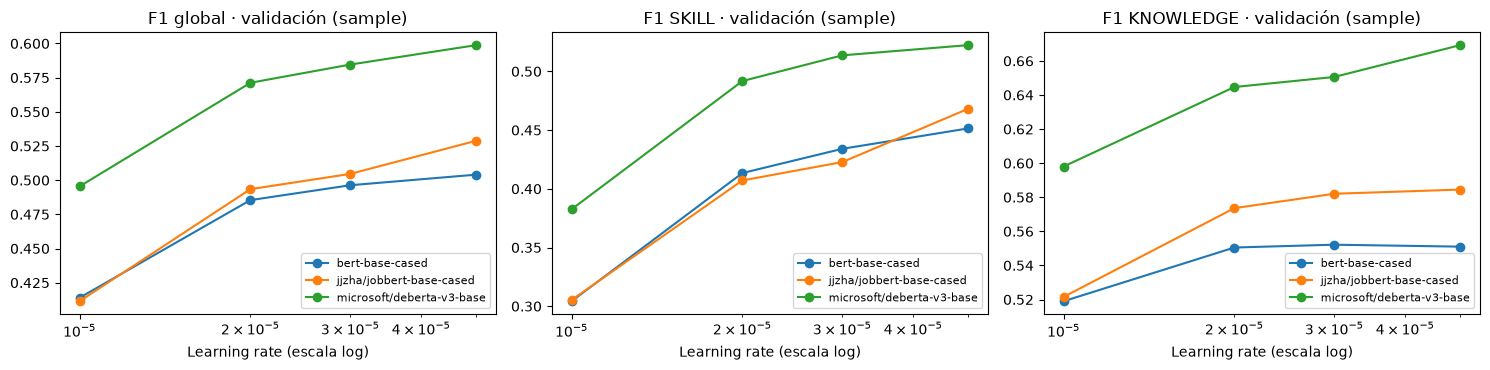

Mejor configuración: microsoft/deberta-v3-base, learning_rate=5e-05 (F1=0.5988)


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for metric, ax, title in zip(["eval_f1", "eval_f1_skill", "eval_f1_knowledge"], axes,
                             ["F1 global", "F1 SKILL", "F1 KNOWLEDGE"]):
    for model_name, grp in search_df.sort_values("learning_rate").groupby("model"):
        ax.plot(grp["learning_rate"], grp[metric], marker="o", label=model_name)
    ax.set_xscale("log")
    ax.set_xlabel("Learning rate (escala log)")
    ax.set_title(f"{title} · validación (sample)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

best = search_df.iloc[0]
BEST_MODEL_NAME, BEST_LR = best["model"], float(best["learning_rate"])
print(f"Mejor configuración: {BEST_MODEL_NAME}, learning_rate={BEST_LR:.0e} (F1={best['eval_f1']:.4f})")

### 2.6 Entrenamiento con la data completa

Entrenamos el mejor modelo con las **4.800 oraciones** de entrenamiento durante 6 épocas (con pocos datos
conviene más de 3 épocas) y nos quedamos con el *checkpoint* con mejor F1 en las 3.174 oraciones de validación.
Tiempo aproximado en una T4: ~5–8 minutos.

In [33]:
FULL_EPOCHS = 6
tokenizer, tokd = prepared[BEST_MODEL_NAME]
train_full, eval_full = tokd["train"], tokd["validation"]
if SMOKE:
    train_full = train_full.shuffle(seed=SEED).select(range(N_TRAIN_SAMPLE))
    eval_full = eval_full.shuffle(seed=SEED).select(range(N_EVAL_SAMPLE))

trainer = build_trainer(BEST_MODEL_NAME, train_full, eval_full, BEST_LR, BATCH_SIZE, FULL_EPOCHS,
                        f"{OUTPUT_DIR}/checkpoints", save=True, max_steps=10 if SMOKE else -1)
start = time.time()
trainer.train()
print(f"Entrenamiento completo en {(time.time() - start) / 60:.1f} minutos")

Some weights of DebertaV2ForTokenClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,F1 Skill,F1 Knowledge
1,0.225600,0.232002,0.468206,0.546831,0.504473,0.418403,0.591487
2,0.151300,0.253955,0.517106,0.622044,0.564741,0.477056,0.651044
3,0.101000,0.266627,0.515312,0.644749,0.572809,0.509344,0.632221
4,0.068900,0.301786,0.565620,0.664617,0.611135,0.560997,0.659014
5,0.033500,0.354069,0.584016,0.674078,0.625823,0.585083,0.665227
6,0.024100,0.365144,0.579439,0.674551,0.623388,0.588182,0.656489


Entrenamiento completo en 2.5 minutos


,epoch,step,eval_loss,eval_f1,eval_f1_skill,eval_f1_knowledge
0,1.0,300,0.232002,0.504473,0.418403,0.591487
1,2.0,600,0.253955,0.564741,0.477056,0.651044
2,3.0,900,0.266627,0.572809,0.509344,0.632221
3,4.0,1200,0.301786,0.611135,0.560997,0.659014
4,5.0,1500,0.354069,0.625823,0.585083,0.665227
5,6.0,1800,0.365144,0.623388,0.588182,0.656489


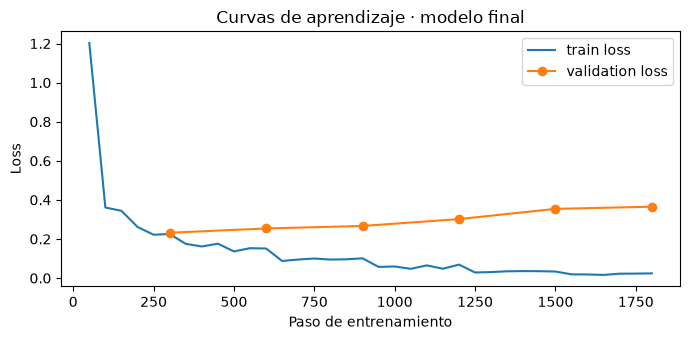

In [34]:
history = pd.DataFrame(trainer.state.log_history)
train_loss = history.dropna(subset=["loss"])[["step", "loss"]]
eval_hist = history.dropna(subset=["eval_loss"])[["epoch", "step", "eval_loss", "eval_f1", "eval_f1_skill", "eval_f1_knowledge"]]
display(eval_hist.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(train_loss["step"], train_loss["loss"], label="train loss")
ax.plot(eval_hist["step"], eval_hist["eval_loss"], marker="o", label="validation loss")
ax.set_xlabel("Paso de entrenamiento")
ax.set_ylabel("Loss")
ax.set_title("Curvas de aprendizaje · modelo final")
ax.legend()
plt.tight_layout()
plt.show()

In [35]:
BEST_MODEL_DIR = f"{OUTPUT_DIR}/best_model"
trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)
print("Mejor modelo guardado en", BEST_MODEL_DIR)

HF_REPO_ID = f"{HF_USER}/{BEST_MODEL_NAME.split('/')[-1].replace('-cased', '')}-skillspan-udea"
if PUSH_TO_HUB:
    from huggingface_hub import notebook_login
    notebook_login()
    trainer.model.push_to_hub(HF_REPO_ID)
    tokenizer.push_to_hub(HF_REPO_ID)

Mejor modelo guardado en outputs/skillspan/best_model


### 2.7 Evaluación y demostración del mejor modelo

#### 2.7.1 Métricas sobre el conjunto de prueba

In [36]:
n_test = 200 if SMOKE else len(tokd["test"])
test_ds = tokd["test"].select(range(n_test))
pred = trainer.predict(test_ds)
true_tags, pred_tags = to_tag_sequences(pred.predictions, pred.label_ids)
print({k: round(v, 4) for k, v in pred.metrics.items() if k.startswith("test_") and "runtime" not in k
       and "per_second" not in k})
print()
print(classification_report(true_tags, pred_tags, digits=4, zero_division=0))

{'test_loss': 0.3144, 'test_precision': 0.6018, 'test_recall': 0.6561, 'test_f1': 0.6278, 'test_f1_skill': 0.5376, 'test_f1_knowledge': 0.7086}

              precision    recall  f1-score   support

   KNOWLEDGE     0.6646    0.7589    0.7086      1157
       SKILL     0.5283    0.5472    0.5376      1091

   micro avg     0.6018    0.6561    0.6278      2248
   macro avg     0.5965    0.6530    0.6231      2248
weighted avg     0.5985    0.6561    0.6256      2248



#### 2.7.2 Línea base clásica: diccionario de spans vistos en entrenamiento

¿Qué tan lejos se llega **memorizando**? Armamos un diccionario con todos los spans de *skill* y *knowledge* del
conjunto de entrenamiento (en minúsculas, con su tipo más frecuente) y etiquetamos el test buscando, palabra por
palabra, la coincidencia **más larga** del diccionario. Es la forma más simple de extraer habilidades sin aprendizaje.

In [37]:
def span_tuples(tokens, tags):
    """Devuelve (inicio, fin, tipo) de cada span en una secuencia BIO."""
    spans, start, kind = [], None, None
    for i, tag in enumerate(tags + ["O"]):
        if start is not None and tag != f"I-{kind}":
            spans.append((start, i, kind))
            start = None
        if tag.startswith("B-") or (tag.startswith("I-") and start is None):
            start, kind = i, tag[2:]
    return spans


type_counts = {}
for ex in dataset["train"]:
    tags = [id2label[t] for t in ex["ner_tags"]]
    for s, e, kind in span_tuples(ex["tokens"], tags):
        key = tuple(w.lower() for w in ex["tokens"][s:e])
        type_counts.setdefault(key, Counter())[kind] += 1
span_dict = {k: c.most_common(1)[0][0] for k, c in type_counts.items()}
MAX_SPAN = max(len(k) for k in span_dict)
print(f"Diccionario: {len(span_dict)} spans distintos (el más largo tiene {MAX_SPAN} palabras)")


def dictionary_tagger(tokens):
    lower, tags, i = [w.lower() for w in tokens], ["O"] * len(tokens), 0
    while i < len(tokens):
        for length in range(min(MAX_SPAN, len(tokens) - i), 0, -1):
            kind = span_dict.get(tuple(lower[i: i + length]))
            if kind:
                tags[i: i + length] = [f"B-{kind}"] + [f"I-{kind}"] * (length - 1)
                i += length
                break
        else:
            i += 1
    return tags


test_tokens = [raw["test"][i]["tokens"][: len(true_tags[i])] for i in range(n_test)]
dict_tags = [dictionary_tagger(tokens) for tokens in test_tokens]


def span_scores(name, predicted):
    rep = classification_report(true_tags, predicted, output_dict=True, zero_division=0)
    return {"modelo": name, "precision": precision_score(true_tags, predicted, zero_division=0),
            "recall": recall_score(true_tags, predicted, zero_division=0), "F1 global": f1_score(true_tags, predicted, zero_division=0),
            "F1 SKILL": rep.get("SKILL", {}).get("f1-score", 0.0), "F1 KNOWLEDGE": rep.get("KNOWLEDGE", {}).get("f1-score", 0.0)}


display(pd.DataFrame([
    span_scores("Diccionario de spans de train (coincidencia más larga)", dict_tags),
    span_scores(f"{BEST_MODEL_NAME} fine-tuned", pred_tags),
]).set_index("modelo").round(4))

Diccionario: 3679 spans distintos (el más largo tiene 23 palabras)


,precision,recall,F1 global,F1 SKILL,F1 KNOWLEDGE
modelo,,,,,
Diccionario de spans de train (coincidencia más larga),0.1252,0.3443,0.1837,0.1230,0.2095
microsoft/deberta-v3-base fine-tuned,0.6018,0.6561,0.6278,0.5376,0.7086


#### 2.7.3 ¿Generaliza a habilidades que nunca vio?

El diccionario, por construcción, solo puede encontrar spans que ya aparecieron en entrenamiento. Separamos los spans
reales del test en **vistos** (su texto está en el diccionario) y **nuevos**, y medimos qué porcentaje recupera
exactamente cada método (mismo tipo y mismos límites).

In [38]:
rows = []
for i, tokens in enumerate(test_tokens):
    model_spans = set(span_tuples(tokens, pred_tags[i]))
    dict_spans = set(span_tuples(tokens, dict_tags[i]))
    for span in span_tuples(tokens, true_tags[i]):
        seen = tuple(w.lower() for w in tokens[span[0]: span[1]]) in span_dict
        rows.append({"tipo": span[2], "visto en train": "visto" if seen else "nuevo",
                     "modelo": span in model_spans, "diccionario": span in dict_spans})
recall_df = pd.DataFrame(rows)
summary_seen = recall_df.groupby(["tipo", "visto en train"]).agg(
    spans=("modelo", "size"), recall_modelo=("modelo", "mean"), recall_diccionario=("diccionario", "mean"))
display(summary_seen.round(3))
print(f"{(recall_df['visto en train'] == 'nuevo').mean():.1%} de los spans del test nunca aparecieron en train")

spans  recall_modelo  recall_diccionario
tipo      visto en train                                          
KNOWLEDGE nuevo             513          0.647               0.000
          visto             644          0.848               0.961
SKILL     nuevo             894          0.527               0.000
          visto             197          0.640               0.787

62.6% de los spans del test nunca aparecieron en train


#### 2.7.4 ¿Cambia el desempeño según el tipo de oferta?

In [39]:
sources = np.array(raw["test"]["source"][:n_test])
by_source = []
for src in ["tech", "house"]:
    idx = np.where(sources == src)[0]
    if len(idx) == 0:
        continue
    t = [true_tags[i] for i in idx]
    p = [pred_tags[i] for i in idx]
    rep = classification_report(t, p, output_dict=True, zero_division=0)
    by_source.append({"fuente": src, "oraciones": len(idx), "F1 global": f1_score(t, p, zero_division=0),
                      "F1 SKILL": rep.get("SKILL", {}).get("f1-score", 0.0),
                      "F1 KNOWLEDGE": rep.get("KNOWLEDGE", {}).get("f1-score", 0.0)})
display(pd.DataFrame(by_source).set_index("fuente").round(4))

,oraciones,F1 global,F1 SKILL,F1 KNOWLEDGE
fuente,,,,
tech,2286,0.6766,0.5354,0.7543
house,1283,0.5700,0.5391,0.6187


#### 2.7.5 Predicción vs. realidad en oraciones del test

In [40]:
def spans_from_tags(tokens, tags, kind):
    out, current = [], []
    for tok, tag in zip(tokens + ["<END>"], tags + ["O"]):
        if tag == f"I-{kind}" and current:
            current.append(tok)
            continue
        if current:
            out.append(" ".join(current))
            current = []
        if tag in (f"B-{kind}", f"I-{kind}"):
            current = [tok]
    return out

shown = 0
for i in range(n_test):
    if not any(t != "O" for t in true_tags[i]) or len(true_tags[i]) < 8:
        continue
    tokens = raw["test"][i]["tokens"][: len(true_tags[i])]
    print(" ".join(tokens))
    for kind in ["SKILL", "KNOWLEDGE"]:
        print(f"   {kind:<9} real:     {spans_from_tags(tokens, true_tags[i], kind)}")
        print(f"   {kind:<9} predicho: {spans_from_tags(tokens, pred_tags[i], kind)}")
    print()
    shown += 1
    if shown == 4:
        break

As a member of our <ORGANIZATION> <ORGANIZATION> <ORGANIZATION> we look first and foremost for people who are passionate around solving business problems through innovation and engineering practices .
   SKILL     real:     ['solving business problems']
   SKILL     predicho: ['solving business problems through innovation and engineering practices']
   KNOWLEDGE real:     ['innovation and engineering practices']
   KNOWLEDGE predicho: []

You'll be required to apply your depth of knowledge and expertise to all aspects of the software development lifecycle as well as partner continuously with your many stakeholders on a daily basis to stay focused on common goals .
   SKILL     real:     ['apply your depth of knowledge and expertise', 'partner continuously with your many stakeholders', 'stay focused on common goals']
   SKILL     predicho: ['apply your depth of knowledge and expertise', 'partner continuously with your many stakeholders']
   KNOWLEDGE real:     ['software development lif

#### 2.7.6 Probando el modelo con una oferta de empleo nueva

In [41]:
extractor = pipeline("token-classification", model=BEST_MODEL_DIR, tokenizer=BEST_MODEL_DIR,
                     aggregation_strategy="simple", device=0 if DEVICE == "cuda" else -1)

job_posting = [
    "We are looking for a Data Scientist with strong experience in Python, SQL and machine learning.",
    "You will design and deploy NLP models and communicate results to non-technical stakeholders.",
    "Knowledge of Docker, Kubernetes and AWS is a plus.",
    "The ideal candidate is able to work independently and manage multiple projects at the same time.",
    "Registered nurse with experience in intensive care and patient monitoring.",
]
for sentence, entities in zip(job_posting, extractor(job_posting)):
    print(sentence)
    for e in entities:
        print(f"   {e['entity_group']:<10} {e['word']:<45} (score {e['score']:.3f})")
    print()

Device set to use cuda:0


Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


We are looking for a Data Scientist with strong experience in Python, SQL and machine learning.
   KNOWLEDGE  Python                                        (score 0.994)
   KNOWLEDGE  SQL                                           (score 0.997)
   KNOWLEDGE  machine learning                              (score 0.998)

You will design and deploy NLP models and communicate results to non-technical stakeholders.
   SKILL      design and deploy NLP models                  (score 0.998)
   SKILL      communicate results to non-technical stakeholders (score 0.998)

Knowledge of Docker, Kubernetes and AWS is a plus.
   KNOWLEDGE  Docker                                        (score 0.994)
   KNOWLEDGE  Kubernetes                                    (score 0.996)
   KNOWLEDGE  AWS                                           (score 0.998)

The ideal candidate is able to work independently and manage multiple projects at the same time.
   SKILL      work independently                            (sco

### 2.8 Conclusiones

- El mejor F1 en validación se alcanzó en la **época 5** de 6 (sección 2.6); el modelo final evaluado y publicado es
  ese *checkpoint*.
- Extraer habilidades es un problema de etiquetado de secuencias **más difícil que el NER clásico**: los spans de
  *skill* son largos y de límites difusos ("work closely with the product team to..."), mientras que los de
  *knowledge* son cortos y parecidos a entidades nombradas. Los F1 por tipo de la sección 2.7.1 lo reflejan.
- Memorizar no basta: el diccionario de spans de entrenamiento (sección 2.7.2) no puede encontrar habilidades nuevas,
  mientras que el modelo sí recupera una parte importante de los spans que nunca vio (sección 2.7.3).
- La búsqueda de la sección 2.5 responde con datos si aporta más un modelo **pre-entrenado en el dominio** (JobBERT) o
  una **arquitectura más moderna** (DeBERTa-v3), frente a BERT genérico del mismo tamaño.
- El **learning rate** sigue siendo crítico: con solo 2.500 oraciones, valores bajos no alcanzan a converger en
  pocas épocas.
- Aplicación directa: con este modelo se puede convertir una oferta de trabajo en una lista estructurada de
  requisitos y compararla con un CV.
- Posibles mejoras: entrenar dos cabezas separadas (una por capa) para permitir spans anidados, usar un CRF sobre
  el encoder, o modelos más grandes / con más pre-entrenamiento del dominio laboral.

### 2.9 Resultados de la parte 2 y liberación de memoria

Guardamos las métricas finales para el resumen de la sección 4 y liberamos la memoria de la GPU antes de la siguiente parte.

In [42]:
FINAL_RESULTS += [
    {"Parte": "2. Habilidades", "Modelo": BEST_MODEL_NAME, "Métrica (test)": "F1 por span",
     "Línea base clásica": f1_score(true_tags, dict_tags, zero_division=0),
     "Modelo fine-tuned": f1_score(true_tags, pred_tags, zero_division=0)},
]

for _name in ["trainer", "model", "tokenized", "prepared", "tokd", "train_sample", "eval_sample", "train_full",
              "eval_full", "tfidf_clf", "X_train", "extractor", "toxicity", "pred", "val_pred", "test_pred"]:
    globals().pop(_name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memoria de GPU en uso tras limpiar: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
display(pd.DataFrame(FINAL_RESULTS[-1:]).set_index("Parte").round(3))

Memoria de GPU en uso tras limpiar: 0.02 GB


,Modelo,Métrica (test),Línea base clásica,Modelo fine-tuned
Parte,,,,
2. Habilidades,microsoft/deberta-v3-base,F1 por span,0.184,0.628


## Parte 3 · Sequence-to-sequence. Desintoxicación de texto (transferencia de estilo)

**Problema:** dado un comentario **tóxico** en inglés (insultos, groserías, agresividad), **reescribirlo** de forma
respetuosa **conservando su significado**. Por ejemplo:
*"dude should have been taken to api, he would be right at home with all the other knuckleheads there"* →
*"It would have been good if he went to api. He would fit in."*

Es un problema **sequence-to-sequence** de *text style transfer*: la entrada y la salida son textos, y el modelo
debe cambiar el **estilo** (tóxico → neutral) sin cambiar el **contenido**.

**Dataset:** [ParaDetox](https://huggingface.co/datasets/s-nlp/paradetox) (Logacheva et al., ACL 2022).
**Modelo base:** [`facebook/bart-base`](https://huggingface.co/facebook/bart-base), un modelo **encoder-decoder** tipo BART.

> ⚠️ **Advertencia de contenido:** los ejemplos de este notebook contienen lenguaje ofensivo, propio del problema que se quiere resolver.


### 3.1 Configuración e importaciones

Cada parte importa lo que usa, para que se pueda volver a ejecutar desde aquí sin depender de las otras.

In [43]:
import gc
import os
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import seaborn as sns
import torch
from datasets import Dataset, DatasetDict, load_dataset
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    pipeline,
    set_seed,
)

SMOKE = os.environ.get("SMOKE", "0") == "1"  # True = corrida rápida de verificación
SEED = 42
MODEL_NAME = "facebook/bart-base"
TOXICITY_CLASSIFIER = "s-nlp/roberta_toxicity_classifier"  # juez automático de toxicidad (solo para evaluar)
MAX_SOURCE_LENGTH = 128
MAX_TARGET_LENGTH = 128
OUTPUT_DIR = "outputs/paradetox"
PUSH_TO_HUB = False
HF_REPO_ID = "jeffespejo/bart-base-paradetox-udea"

set_seed(SEED)
# transformers 5 eliminó `warmup_ratio`; ahora `warmup_steps` acepta una fracción de los pasos totales.
import inspect
WARMUP = ({"warmup_ratio": 0.1} if "warmup_ratio" in inspect.signature(Seq2SeqTrainingArguments).parameters
          else {"warmup_steps": 0.1})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()
print(f"Dispositivo: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"SMOKE = {SMOKE}")

Dispositivo: cuda (NVIDIA GeForce RTX 5070 Ti)
SMOKE = False


### 3.2 Descripción de la base de datos

| Aspecto | Descripción |
|---|---|
| **Dominio** | Comentarios reales en inglés de Reddit, Twitter y Jigsaw (comentarios de Wikipedia) marcados como tóxicos. |
| **Tipo de problema** | Sequence-to-sequence: **transferencia de estilo** (*detoxification*), una forma de paráfrasis controlada. |
| **Entrada (X)** | `en_toxic_comment`: un comentario tóxico (normalmente una frase). |
| **Salida (y)** | `en_neutral_comment`: la misma idea reescrita sin toxicidad, escrita por anotadores humanos. |
| **Tamaño** | 19.744 pares (toxic, neutral), pero solo ~11.900 comentarios tóxicos **distintos**: muchos tienen 2 o 3 reescrituras válidas. |
| **Cómo se construyó** | *Crowdsourcing* en 3 etapas: unos anotadores reescribían, otros verificaban que la versión nueva conservara el sentido y que no fuera tóxica. |
| **Licencia** | OpenRAIL++. |

**Utilidad.** Moderación de contenido "constructiva": en lugar de borrar un comentario, una plataforma puede
**sugerir** al usuario una versión respetuosa antes de publicarlo. También sirve para limpiar datos de
entrenamiento de chatbots y para asistentes de escritura que suavizan el tono de emails o mensajes.

**Por qué es difícil.** Borrar las groserías no basta: el modelo debe decidir qué partes son "ataque" y qué partes
son "contenido", y reconstruir una frase gramatical que diga lo mismo. Además hay un equilibrio natural:
copiar la entrada conserva el 100 % del contenido pero sigue siendo tóxica, y responder siempre "ok" no es tóxico
pero pierde todo el contenido.

**Métricas** (como en el paper de ParaDetox):
- **BLEU** y **chrF** contra las reescrituras humanas: miden qué tanto se parece la salida a una buena reescritura
  (contenido + fluidez). Usamos **todas** las referencias disponibles de cada comentario.
- **STA** (*style transfer accuracy*): % de salidas que un clasificador de toxicidad independiente
  ([`s-nlp/roberta_toxicity_classifier`](https://huggingface.co/s-nlp/roberta_toxicity_classifier)) considera **no tóxicas**.

In [44]:
raw = load_dataset("s-nlp/paradetox")["train"]
df = raw.to_pandas().rename(columns={"en_toxic_comment": "toxic", "en_neutral_comment": "neutral"})
df["toxic"], df["neutral"] = df["toxic"].fillna("").str.strip(), df["neutral"].fillna("").str.strip()
df = df[(df["toxic"] != "") & (df["neutral"] != "")].reset_index(drop=True)
print(f"Pares válidos: {len(df)} | comentarios tóxicos distintos: {df['toxic'].nunique()}")

Pares válidos: 19744 | comentarios tóxicos distintos: 11927


#### Partición train / validación / test **agrupada por comentario tóxico**

El dataset viene en un único bloque. Si separáramos los **pares** al azar, el mismo comentario tóxico podría quedar
en train (con una reescritura) y en test (con otra): el modelo estaría "viendo el examen". Por eso partimos los
**comentarios tóxicos distintos** (80 % / 10 % / 10 %) y todas sus reescrituras van al mismo conjunto.

In [45]:
unique_toxic = df["toxic"].drop_duplicates().sample(frac=1.0, random_state=SEED).tolist()
n = len(unique_toxic)
split_of = {t: "train" for t in unique_toxic[: int(0.8 * n)]}
split_of.update({t: "validation" for t in unique_toxic[int(0.8 * n): int(0.9 * n)]})
split_of.update({t: "test" for t in unique_toxic[int(0.9 * n):]})
df["split"] = df["toxic"].map(split_of)

pairs = DatasetDict({
    name: Dataset.from_pandas(df[df["split"] == name][["toxic", "neutral"]].reset_index(drop=True))
    for name in ["train", "validation", "test"]
})
for name in ["train", "validation", "test"]:
    part = df[df["split"] == name]
    print(f"{name:>10}: {len(part):>6} pares | {part['toxic'].nunique():>6} comentarios tóxicos distintos")
assert not (set(df.loc[df.split == "train", "toxic"]) & set(df.loc[df.split == "test", "toxic"])), "fuga train/test"

     train:  15765 pares |   9541 comentarios tóxicos distintos
validation:   1987 pares |   1193 comentarios tóxicos distintos
      test:   1992 pares |   1193 comentarios tóxicos distintos


### 3.3 Análisis exploratorio (EDA)

#### 3.3.1 Algunos ejemplos (con todas sus reescrituras)

In [46]:
multi_ref = df.groupby("toxic")["neutral"].apply(list)
for toxic in [multi_ref.index[i] for i in np.where(multi_ref.str.len().values >= 2)[0][:3]] + [df["toxic"].iloc[5]]:
    print(f"TÓXICO:   {toxic}")
    for ref in multi_ref[toxic]:
        print(f"NEUTRAL:  {ref}")
    print("-" * 90)

TÓXICO:   ! but it 's supposed to rain & shit .
NEUTRAL:  ! but it 's supposed to rain.
NEUTRAL:  ! but it 's supposed to rain & stop .
------------------------------------------------------------------------------------------
TÓXICO:   ! you 're getting your ass kicked .
NEUTRAL:  You are doing something wrong.
NEUTRAL:  you 're getting kicked
------------------------------------------------------------------------------------------
TÓXICO:   ! you gotta be shitting me .
NEUTRAL:  you gotta be playing with me
NEUTRAL:  You gotta be kidding me.
------------------------------------------------------------------------------------------
TÓXICO:   i hope they beat each other silly .
NEUTRAL:  I think they beat each other
------------------------------------------------------------------------------------------


#### 3.3.2 Referencias por comentario y longitudes

neutral
1    5973
2    4092
3    1861
4       1


,toxic_words,neutral_words,length_ratio
count,19744.00,19744.00,19744.00
mean,11.87,9.32,0.78
std,4.02,4.03,0.19
min,1.00,1.00,0.05
25%,8.00,6.00,0.67
50%,11.00,9.00,0.80
75%,15.00,12.00,0.90
max,20.00,27.00,10.00


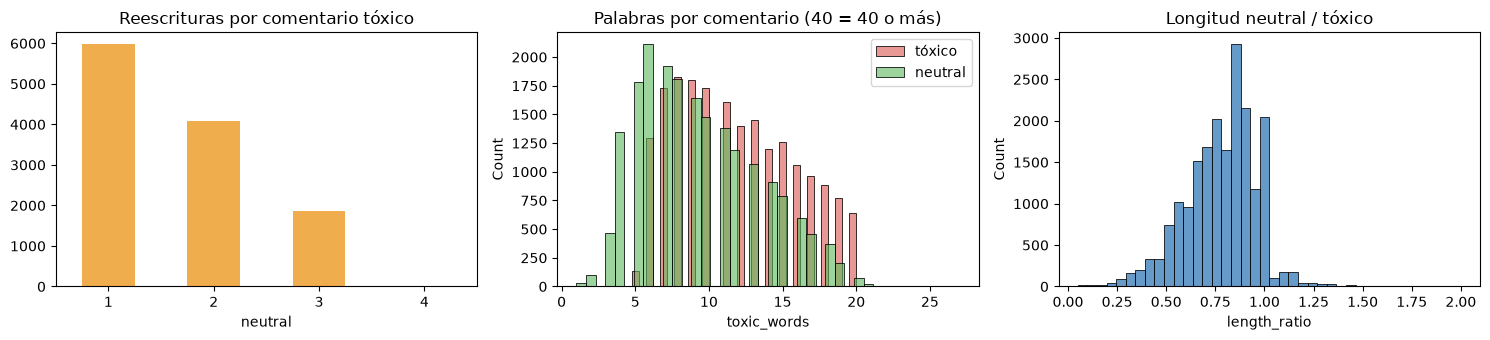

In [47]:
refs_per_toxic = multi_ref.str.len()
print(refs_per_toxic.value_counts().sort_index().rename("comentarios tóxicos").to_string())

df["toxic_words"] = df["toxic"].str.split().str.len()
df["neutral_words"] = df["neutral"].str.split().str.len()
df["length_ratio"] = df["neutral_words"] / df["toxic_words"]
display(df[["toxic_words", "neutral_words", "length_ratio"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
refs_per_toxic.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#f0ad4e")
axes[0].set_title("Reescrituras por comentario tóxico")
axes[0].tick_params(axis="x", rotation=0)
sns.histplot(df["toxic_words"].clip(upper=40), bins=40, ax=axes[1], color="#d9534f", label="tóxico", alpha=0.6)
sns.histplot(df["neutral_words"].clip(upper=40), bins=40, ax=axes[1], color="#5cb85c", label="neutral", alpha=0.6)
axes[1].set_title("Palabras por comentario (40 = 40 o más)")
axes[1].legend()
sns.histplot(df["length_ratio"].clip(upper=2), bins=40, ax=axes[2], color="#337ab7")
axes[2].set_title("Longitud neutral / tóxico")
plt.tight_layout()
plt.show()

#### 3.3.3 ¿Qué palabras eliminan los anotadores?

Contamos las palabras que aparecen en el comentario tóxico pero **no** en su reescritura. Es una forma directa de
ver qué considera "tóxico" el dataset.

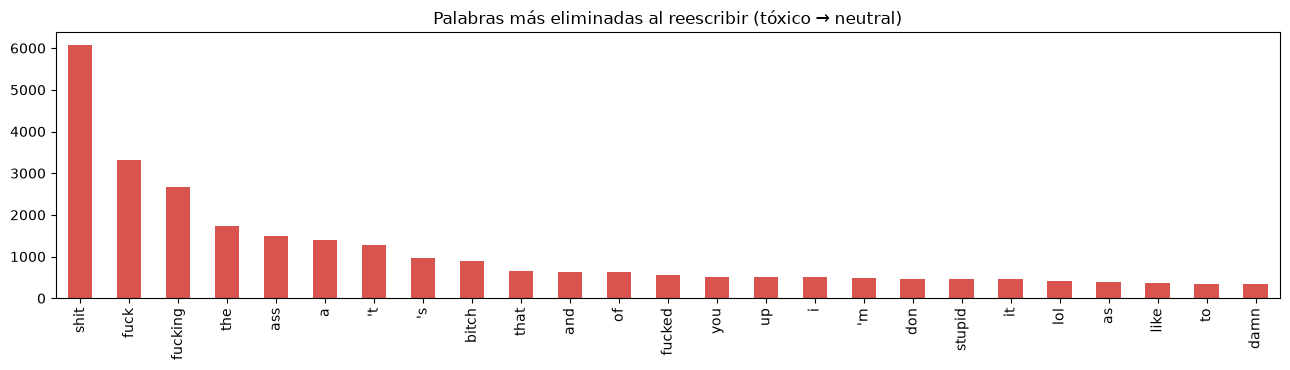

In [48]:
def words(text):
    return re.findall(r"[a-z']+", text.lower())

removed = Counter()
for toxic, neutral in zip(df["toxic"], df["neutral"]):
    removed.update(set(words(toxic)) - set(words(neutral)))

top_removed = pd.Series(dict(removed.most_common(25)))
fig, ax = plt.subplots(figsize=(13, 3.8))
top_removed.plot(kind="bar", ax=ax, color="#d9534f")
ax.set_title("Palabras más eliminadas al reescribir (tóxico → neutral)")
plt.tight_layout()
plt.show()

#### 3.3.4 Longitud en tokens

In [49]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
src_tok = np.array([len(x) for x in tokenizer(df["toxic"].tolist())["input_ids"]])
tgt_tok = np.array([len(x) for x in tokenizer(df["neutral"].tolist())["input_ids"]])
print(f"Entradas con ≤ {MAX_SOURCE_LENGTH} tokens: {np.mean(src_tok <= MAX_SOURCE_LENGTH):.2%} (máx. {src_tok.max()})")
print(f"Salidas con ≤ {MAX_TARGET_LENGTH} tokens: {np.mean(tgt_tok <= MAX_TARGET_LENGTH):.2%} (máx. {tgt_tok.max()})")

Entradas con ≤ 128 tokens: 100.00% (máx. 38)
Salidas con ≤ 128 tokens: 100.00% (máx. 37)


**Hallazgos del EDA**
- Los textos son cortos (≈ 12 palabras) y la reescritura suele ser algo **más corta** que el original: gran parte del
  trabajo es **eliminar** el ataque y reacomodar la frase.
- Las palabras más eliminadas son groserías e insultos, pero también intensificadores ("fucking", "damn") cuya
  eliminación no cambia el sentido. Un buen modelo debe hacer más que borrar: a veces reemplaza ("idiot" → "person").
- Muchos comentarios tienen varias reescrituras válidas, por eso evaluamos con **múltiples referencias**.
- Todo cabe en 128 tokens, así que no hay que recortar nada.

### 3.4 Tokenización y preparación de los datos

In [50]:
def preprocess(batch):
    model_inputs = tokenizer(batch["toxic"], max_length=MAX_SOURCE_LENGTH, truncation=True)
    labels = tokenizer(text_target=batch["neutral"], max_length=MAX_TARGET_LENGTH, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized = pairs.map(preprocess, batched=True, remove_columns=["toxic", "neutral"])
print(tokenized)

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 15765
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1987
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1992
    })
})


#### Métricas y función de entrenamiento reutilizable

Durante el entrenamiento medimos BLEU y chrF contra la reescritura del par (una referencia). La evaluación final con
todas las referencias y STA se hace en la sección 3.7.

In [51]:
def decode(ids):
    ids = np.where(ids != -100, ids, tokenizer.pad_token_id)
    return [t.strip() for t in tokenizer.batch_decode(ids, skip_special_tokens=True)]


def compute_metrics(eval_pred):
    preds, labels = eval_pred
    if isinstance(preds, tuple):
        preds = preds[0]
    hyps, refs = decode(preds), decode(labels)
    return {
        "bleu": sacrebleu.corpus_bleu(hyps, [refs]).score,
        "chrf": sacrebleu.corpus_chrf(hyps, [refs]).score,
    }


def build_trainer(train_ds, eval_ds, learning_rate, batch_size, epochs, output_dir,
                  num_beams=1, save=False, max_steps=-1):
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    # transformers 5 carga los pesos en el dtype del checkpoint; el fp16 mixto necesita los pesos en fp32.
    model = model.float()
    args = Seq2SeqTrainingArguments(
        output_dir=output_dir,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        num_train_epochs=epochs,
        max_steps=max_steps,
        weight_decay=0.01,
        **WARMUP,
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch" if save else "no",
        load_best_model_at_end=save,
        metric_for_best_model="bleu",
        save_total_limit=1,
        logging_steps=2 if SMOKE else 50,
        predict_with_generate=True,
        generation_max_length=MAX_TARGET_LENGTH,
        generation_num_beams=num_beams,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )
    return Seq2SeqTrainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,
        data_collator=DataCollatorForSeq2Seq(tokenizer, model=model),
        compute_metrics=compute_metrics,
    )


def free_memory(*objects):
    for obj in objects:
        del obj
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### 3.5 Búsqueda de hiperparámetros sobre un *sample*

Comparamos configuraciones con **3.000 pares** de entrenamiento y **300** de validación (2 épocas, decodificación
*greedy* para ir rápido):
- **Learning rate**: `2e-5`, `5e-5`, `1e-4`.
- **Batch size**: `16` y `32`.

Elegimos la configuración con mejor **BLEU** en validación.

In [52]:
if SMOKE:
    N_TRAIN_SAMPLE, N_EVAL_SAMPLE, SEARCH_EPOCHS = 32, 16, 1
    LR_GRID, BS_GRID = [5e-5, 1e-4], [16]
else:
    N_TRAIN_SAMPLE, N_EVAL_SAMPLE, SEARCH_EPOCHS = 3000, 300, 2
    LR_GRID, BS_GRID = [2e-5, 5e-5, 1e-4], [16, 32]

train_sample = tokenized["train"].shuffle(seed=SEED).select(range(N_TRAIN_SAMPLE))
eval_sample = tokenized["validation"].shuffle(seed=SEED).select(range(N_EVAL_SAMPLE))

results = []
for bs in BS_GRID:
    for lr in LR_GRID:
        start = time.time()
        trainer = build_trainer(train_sample, eval_sample, lr, bs, SEARCH_EPOCHS, f"{OUTPUT_DIR}/search")
        trainer.train()
        metrics = trainer.evaluate()
        elapsed = time.time() - start
        results.append({
            "learning_rate": lr, "batch_size": bs, "eval_bleu": metrics["eval_bleu"],
            "eval_chrf": metrics["eval_chrf"], "eval_loss": metrics["eval_loss"], "minutes": elapsed / 60,
        })
        print(f"lr={lr:.0e} bs={bs} -> BLEU={metrics['eval_bleu']:.2f} chrF={metrics['eval_chrf']:.2f} ({elapsed/60:.1f} min)")
        free_memory(trainer)

search_df = pd.DataFrame(results).sort_values("eval_bleu", ascending=False).reset_index(drop=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
search_df.to_csv(f"{OUTPUT_DIR}/hyperparameter_search.csv", index=False)
display(search_df.style.format({"learning_rate": "{:.0e}", "eval_bleu": "{:.2f}", "eval_chrf": "{:.2f}",
                                "eval_loss": "{:.4f}", "minutes": "{:.1f}"})
        .highlight_max(subset=["eval_bleu"], color="#c8e6c9"))

Epoch,Training Loss,Validation Loss,Bleu,Chrf
1,1.250100,1.073705,49.827452,74.448080
2,1.106100,1.052963,49.503871,74.099353


The following generation flags are not valid and may be ignored: ['early_stopping']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


That's 100 lines that end in a tokenized period ('.')


... (10 outputs left out)

lr=5e-05 bs=32 -> BLEU=51.69 chrF=74.67 (0.3 min)


Epoch,Training Loss,Validation Loss,Bleu,Chrf
1,1.587000,1.035215,53.098230,73.037063
2,0.927600,1.006916,52.793191,74.807526


lr=1e-04 bs=32 -> BLEU=52.79 chrF=74.81 (0.2 min)


,learning_rate,batch_size,eval_bleu,eval_chrf,eval_loss,minutes
0,1e-04,16,52.95,75.31,1.0093,0.4
1,1e-04,32,52.79,74.81,1.0069,0.2
2,5e-05,16,52.06,74.94,1.0037,0.4
3,5e-05,32,51.69,74.67,1.0088,0.3
4,2e-05,32,49.58,74.38,1.0786,0.3
5,2e-05,16,49.50,74.10,1.0530,0.4


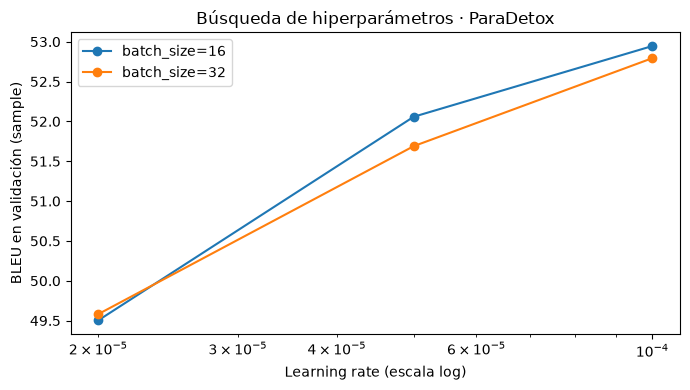

Mejor configuración: learning_rate=1e-04, batch_size=16 (BLEU=52.95)


In [53]:
fig, ax = plt.subplots(figsize=(7, 4))
for bs, grp in search_df.sort_values("learning_rate").groupby("batch_size"):
    ax.plot(grp["learning_rate"], grp["eval_bleu"], marker="o", label=f"batch_size={bs}")
ax.set_xscale("log")
ax.set_xlabel("Learning rate (escala log)")
ax.set_ylabel("BLEU en validación (sample)")
ax.set_title("Búsqueda de hiperparámetros · ParaDetox")
ax.legend()
plt.tight_layout()
plt.show()

best = search_df.iloc[0]
BEST_LR, BEST_BS = float(best["learning_rate"]), int(best["batch_size"])
print(f"Mejor configuración: learning_rate={BEST_LR:.0e}, batch_size={BEST_BS} (BLEU={best['eval_bleu']:.2f})")

### 3.6 Entrenamiento con la data completa

Entrenamos con **todos los pares de entrenamiento** usando la mejor configuración durante 4 épocas, con *beam search*
(4 haces) en validación, y guardamos el *checkpoint* con mejor BLEU. Tiempo aproximado en una T4: ~15–20 minutos.

In [54]:
FULL_EPOCHS = 4
train_full, eval_full = tokenized["train"], tokenized["validation"]
if SMOKE:
    train_full, eval_full = train_sample, eval_sample

trainer = build_trainer(train_full, eval_full, BEST_LR, BEST_BS, FULL_EPOCHS, f"{OUTPUT_DIR}/checkpoints",
                        num_beams=4, save=True, max_steps=10 if SMOKE else -1)
start = time.time()
trainer.train()
print(f"Entrenamiento completo en {(time.time() - start) / 60:.1f} minutos")

Epoch,Training Loss,Validation Loss,Bleu,Chrf
1,1.103400,1.016108,57.490015,77.156743
2,0.851200,0.982148,56.827937,76.490223
3,0.670200,0.996003,57.037759,76.805266
4,0.501700,1.023746,56.758260,76.652676


That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


... (5 outputs left out)

It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Entrenamiento completo en 5.5 minutos


,epoch,step,eval_loss,eval_bleu,eval_chrf
0,1.0,986,1.016108,57.490015,77.156743
1,2.0,1972,0.982148,56.827937,76.490223
2,3.0,2958,0.996003,57.037759,76.805266
3,4.0,3944,1.023746,56.758260,76.652676


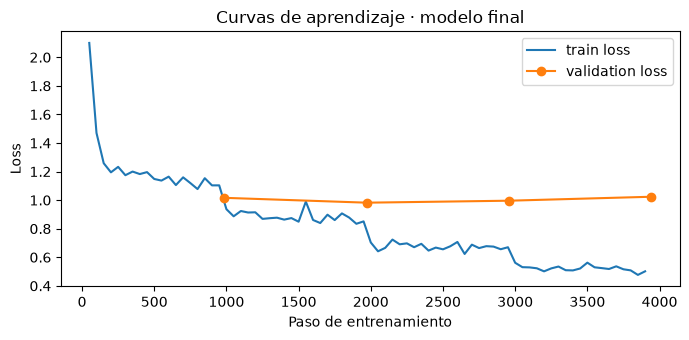

In [55]:
history = pd.DataFrame(trainer.state.log_history)
train_loss = history.dropna(subset=["loss"])[["step", "loss"]]
eval_hist = history.dropna(subset=["eval_loss"])[["epoch", "step", "eval_loss", "eval_bleu", "eval_chrf"]]
display(eval_hist.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(train_loss["step"], train_loss["loss"], label="train loss")
ax.plot(eval_hist["step"], eval_hist["eval_loss"], marker="o", label="validation loss")
ax.set_xlabel("Paso de entrenamiento")
ax.set_ylabel("Loss")
ax.set_title("Curvas de aprendizaje · modelo final")
ax.legend()
plt.tight_layout()
plt.show()

In [56]:
BEST_MODEL_DIR = f"{OUTPUT_DIR}/best_model"
trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)
print("Mejor modelo guardado en", BEST_MODEL_DIR)

if PUSH_TO_HUB:
    from huggingface_hub import notebook_login
    notebook_login()
    trainer.model.push_to_hub(HF_REPO_ID)
    tokenizer.push_to_hub(HF_REPO_ID)

Mejor modelo guardado en outputs/paradetox/best_model


### 3.7 Evaluación y demostración del mejor modelo

#### 3.7.1 Evaluación en test con múltiples referencias y STA

Evaluamos sobre los **comentarios tóxicos distintos** del test, comparando cada salida con **todas** sus reescrituras
humanas. Comparamos cuatro sistemas:
- **Copiar la entrada** (línea base trivial): conserva todo el contenido, pero sigue siendo tóxica.
- **Borrar palabras tóxicas** (línea base clásica, sin aprendizaje profundo): a partir del split de train armamos un
  léxico con las palabras que los anotadores eliminan en al menos el 80 % de los casos (entre las que aparecen al menos 10 veces), y simplemente las borramos.
- **Reescritura humana** (techo de referencia): la primera reescritura de los anotadores.
- **Nuestro modelo** *fine-tuned*.

Some weights of the model checkpoint at s-nlp/roberta_toxicity_classifier were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Device set to use cuda:0


Léxico tóxico: 126 palabras, p. ej. ['absolute', 'af', 'arrogant', 'ass', 'asses', 'asshole', 'assholes', 'aww', 'balls', 'bastard', 'bastards', 'bitch']


That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Comentarios tóxicos evaluados: 1193


,BLEU,chrF,STA (% no tóxico)
sistema,,,
Copiar la entrada (línea base),54.21,76.57,0.00
Borrar palabras del léxico tóxico (línea base clásica),63.37,79.28,85.83
Reescritura humana (referencia),NaN,NaN,94.30
"facebook/bart-base fine-tuned (lr=1e-04, bs=16)",66.35,80.38,86.92


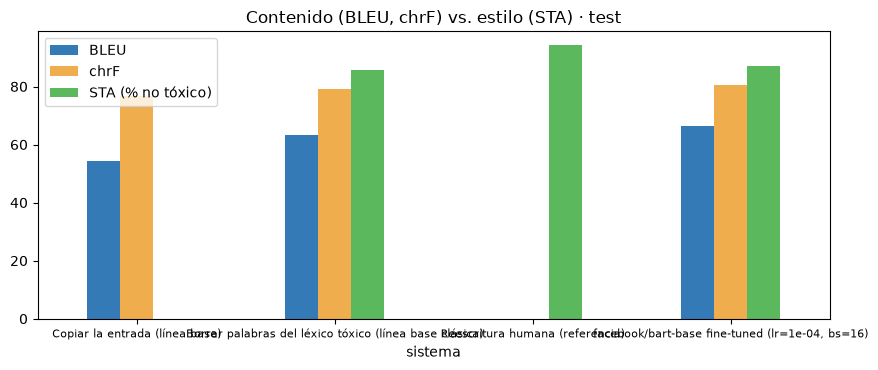

In [57]:
model = trainer.model.eval()
toxicity = pipeline("text-classification", model=TOXICITY_CLASSIFIER, device=0 if DEVICE == "cuda" else -1)

test_groups = df[df["split"] == "test"].groupby("toxic", sort=False)["neutral"].apply(list)
if SMOKE:
    test_groups = test_groups.head(40)
test_inputs, test_refs = test_groups.index.tolist(), test_groups.tolist()


def detoxify(texts, batch_size=64, num_beams=4):
    outputs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i: i + batch_size], max_length=MAX_SOURCE_LENGTH, truncation=True,
                        padding=True, return_tensors="pt").to(model.device)
        with torch.no_grad():
            gen = model.generate(**enc, max_length=MAX_TARGET_LENGTH, num_beams=num_beams)
        outputs.extend(t.strip() for t in tokenizer.batch_decode(gen, skip_special_tokens=True))
    return outputs


def toxic_prob(texts):
    preds = toxicity(texts, batch_size=64, truncation=True, top_k=None)
    return np.array([next(p["score"] for p in pred if p["label"] == "toxic") for pred in preds])


def multi_ref_streams(refs):
    """sacrebleu espera listas de referencias de igual largo: rellenamos repitiendo la primera
    (una referencia duplicada no cambia BLEU ni chrF)."""
    k = max(len(r) for r in refs)
    return [[r[j] if j < len(r) else r[0] for r in refs] for j in range(k)]


def evaluate_system(name, hyps, with_refs=True):
    row = {"sistema": name, "STA (% no tóxico)": 100 * float(np.mean(toxic_prob(hyps) < 0.5))}
    if with_refs:
        streams = multi_ref_streams(test_refs)
        row["BLEU"] = sacrebleu.corpus_bleu(hyps, streams).score
        row["chrF"] = sacrebleu.corpus_chrf(hyps, streams).score
    return row


# Línea base clásica: léxico de palabras que los anotadores eliminan casi siempre (aprendido SOLO de train).
train_pairs = df[df["split"] == "train"]
seen_in_toxic, removed_in_train = Counter(), Counter()
for toxic, neutral in zip(train_pairs["toxic"], train_pairs["neutral"]):
    toxic_words = set(words(toxic))
    seen_in_toxic.update(toxic_words)
    removed_in_train.update(toxic_words - set(words(neutral)))
MIN_COUNT = 3 if SMOKE else 10
TOXIC_LEXICON = sorted(w for w, n in seen_in_toxic.items() if n >= MIN_COUNT and removed_in_train[w] / n >= 0.8)
lexicon_re = re.compile(r"\b(?:" + "|".join(map(re.escape, TOXIC_LEXICON)) + r")\b", flags=re.IGNORECASE)
print(f"Léxico tóxico: {len(TOXIC_LEXICON)} palabras, p. ej. {TOXIC_LEXICON[:12]}")


def delete_toxic_words(text):
    cleaned = lexicon_re.sub("", text)
    cleaned = re.sub(r"\s+([.,!?;:])", r"\1", re.sub(r"\s{2,}", " ", cleaned)).strip()
    return cleaned or text


rule_outputs = [delete_toxic_words(t) for t in test_inputs]
model_outputs = detoxify(test_inputs)
comparison = pd.DataFrame([
    evaluate_system("Copiar la entrada (línea base)", test_inputs),
    evaluate_system("Borrar palabras del léxico tóxico (línea base clásica)", rule_outputs),
    evaluate_system("Reescritura humana (referencia)", [r[0] for r in test_refs], with_refs=False),
    evaluate_system(f"{MODEL_NAME} fine-tuned (lr={BEST_LR:.0e}, bs={BEST_BS})", model_outputs),
]).set_index("sistema")[["BLEU", "chrF", "STA (% no tóxico)"]]
print(f"Comentarios tóxicos evaluados: {len(test_inputs)}")
display(comparison.round(2))

comparison.plot(kind="bar", figsize=(9, 3.8), rot=0, color=["#337ab7", "#f0ad4e", "#5cb85c"])
plt.title("Contenido (BLEU, chrF) vs. estilo (STA) · test")
plt.xticks(fontsize=8)
plt.tight_layout()
plt.show()

**Cómo leer la tabla.** Copiar la entrada obtiene un BLEU alto (comparte muchas palabras con la referencia) pero un STA
muy bajo: el texto sigue siendo tóxico. Un buen modelo de desintoxicación tiene que lograr **las dos cosas**: un STA
cercano al de las reescrituras humanas y, al mismo tiempo, un BLEU/chrF alto que muestre que conservó el contenido.

#### 3.7.2 Ejemplos del test: entrada, referencia y salida del modelo

In [58]:
sample_idx = list(range(min(5, len(test_inputs))))
out_tox = toxic_prob([model_outputs[i] for i in sample_idx])
for j, i in enumerate(sample_idx):
    print(f"TÓXICO:     {test_inputs[i]}")
    print(f"REFERENCIA: {test_refs[i][0]}")
    print(f"MODELO:     {model_outputs[i]}   (prob. tóxico = {out_tox[j]:.2f})")
    print("-" * 90)

TÓXICO:     the reason they dont exist is because neither is a pathological liar like trump .
REFERENCIA: The reason they don't exist is because neither lies like trump
MODELO:     the reason they dont exist is because neither is a pathological liar like trump .   (prob. tóxico = 1.00)
------------------------------------------------------------------------------------------
TÓXICO:     i hope they beat each other silly .
REFERENCIA: I think they beat each other
MODELO:     I hope they beat each other.   (prob. tóxico = 0.95)
------------------------------------------------------------------------------------------
TÓXICO:     honestly catcalling really sounds stupid .
REFERENCIA: It's not wise to catcall frankly.
MODELO:     honestly catcalling really sounds unsuitable.   (prob. tóxico = 0.00)
------------------------------------------------------------------------------------------
TÓXICO:     we arecountry of losers and abusers .
REFERENCIA: We arecountry of not talented people.
MOD

#### 3.7.3 Probando el modelo con frases nuevas

In [59]:
new_comments = [
    "This is the dumbest idea I have ever heard, are you serious?",
    "Shut up and stop wasting everyone's time with your stupid questions.",
    "The referee was a complete idiot and ruined the damn game.",
    "Who the hell wrote this garbage code? It doesn't even compile.",
]
outputs = detoxify(new_comments)
before, after = toxic_prob(new_comments), toxic_prob(outputs)
for text, out, b, a in zip(new_comments, outputs, before, after):
    print(f"ANTES   ({b:.2f}): {text}")
    print(f"DESPUÉS ({a:.2f}): {out}\n")

ANTES   (1.00): This is the dumbest idea I have ever heard, are you serious?
DESPUÉS (0.00): This is the worst idea I have ever heard, are you serious?

ANTES   (1.00): Shut up and stop wasting everyone's time with your stupid questions.
DESPUÉS (0.00): Stop wasting everyone's time with your questions.

ANTES   (1.00): The referee was a complete idiot and ruined the damn game.
DESPUÉS (0.00): The referee ruined the game.

ANTES   (0.98): Who the hell wrote this garbage code? It doesn't even compile.
DESPUÉS (0.00): Who wrote this code? It doesn't even compile.



### 3.8 Conclusiones

- El mejor BLEU en validación se alcanzó en la **primera época** y después bajó levemente (sección 3.6). Como se
  conserva el mejor *checkpoint*, el modelo final evaluado y publicado es el de la época 1.
- La desintoxicación es un problema **seq2seq** distinto al resumen o la traducción: entrada y salida están en el mismo
  idioma y son casi del mismo largo, pero el modelo debe **cambiar el estilo sin perder el contenido**.
- Un modelo *encoder-decoder* pre-entrenado como BART aprende esta transformación con solo ~16.000 pares, porque ya
  sabe generar inglés fluido; el *fine-tuning* le enseña **qué** cambiar.
- Evaluar bien exige más de una métrica: BLEU/chrF por sí solos premian copiar la entrada, y STA por sí solo premia
  respuestas vacías. La tabla de la sección 3.7.1 muestra ambos ejes juntos.
- La línea base clásica de **borrar palabras de un léxico tóxico** resultó sorprendentemente competitiva (sección 3.7.1):
  buena parte de las reescrituras de ParaDetox consiste en eliminar groserías. El modelo la supera en todas las métricas,
  pero por un margen moderado; su ventaja real está en los casos que requieren **reformular** (p. ej. *dumbest* → *worst*,
  quitar un insulto sin dejar la frase rota), que se ven en las secciones 3.7.2 y 3.7.3.
- Partir los datos **agrupando por comentario tóxico** evita una fuga de información que inflaría las métricas.
- El **learning rate** fue el hiperparámetro más sensible en la búsqueda (sección 3.5).
- Limitaciones: el clasificador de toxicidad también se equivoca (sarcasmo, toxicidad implícita) y el modelo puede
  suavizar demasiado o cambiar levemente el sentido. Mejoras posibles: `bart-large`, medir similitud semántica
  (p. ej. con *sentence embeddings*) y evaluación humana.

### 3.9 Resultados de la parte 3 y liberación de memoria

Guardamos las métricas finales para el resumen de la sección 4 y liberamos la memoria de la GPU antes de la siguiente parte.

In [60]:
_rule_row = [i for i in comparison.index if "léxico" in i][0]
FINAL_RESULTS += [
    {"Parte": "3. Desintoxicación", "Modelo": MODEL_NAME, "Métrica (test)": "BLEU",
     "Línea base clásica": comparison.loc[_rule_row, "BLEU"], "Modelo fine-tuned": comparison.iloc[-1]["BLEU"]},
    {"Parte": "3. Desintoxicación", "Modelo": MODEL_NAME, "Métrica (test)": "STA (% no tóxico)",
     "Línea base clásica": comparison.loc[_rule_row, "STA (% no tóxico)"],
     "Modelo fine-tuned": comparison.iloc[-1]["STA (% no tóxico)"]},
]

for _name in ["trainer", "model", "tokenized", "prepared", "tokd", "train_sample", "eval_sample", "train_full",
              "eval_full", "tfidf_clf", "X_train", "extractor", "toxicity", "pred", "val_pred", "test_pred"]:
    globals().pop(_name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memoria de GPU en uso tras limpiar: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
display(pd.DataFrame(FINAL_RESULTS[-2:]).set_index("Parte").round(3))

Memoria de GPU en uso tras limpiar: 0.02 GB


,Modelo,Métrica (test),Línea base clásica,Modelo fine-tuned
Parte,,,,
3. Desintoxicación,facebook/bart-base,BLEU,63.371,66.355
3. Desintoxicación,facebook/bart-base,STA (% no tóxico),85.834,86.924


## 4. Resumen de resultados y conclusiones generales

### 4.1 Resultados en test de los tres mejores modelos frente a su línea base clásica

In [61]:
import pandas as pd

results_df = pd.DataFrame(FINAL_RESULTS)
results_df["Mejora"] = results_df["Modelo fine-tuned"] - results_df["Línea base clásica"]
display(results_df.set_index(["Parte", "Métrica (test)"]).round(3))

Modelo  \
Parte              Métrica (test)                                 
1. Emociones       Micro-F1             FacebookAI/roberta-base   
                   Macro-F1             FacebookAI/roberta-base   
2. Habilidades     F1 por span        microsoft/deberta-v3-base   
3. Desintoxicación BLEU                      facebook/bart-base   
                   STA (% no tóxico)         facebook/bart-base   

                                      Línea base clásica  Modelo fine-tuned  \
Parte              Métrica (test)                                             
1. Emociones       Micro-F1                        0.554              0.603   
                   Macro-F1                        0.420              0.523   
2. Habilidades     F1 por span                     0.184              0.628   
3. Desintoxicación BLEU                           63.371             66.355   
                   STA (% no tóxico)              85.834             86.924   

                                      Mejora  
Parte              Métrica (test)             
1. Emociones       Micro-F1            0.049  
                   Macro-F1            0.103  
2. Habilidades     F1 por span         0.444  
3. Desintoxicación BLEU                2.984  
                   STA (% no tóxico)   1.090

### 4.2 Conclusiones generales

- **Un mismo principio, tres tipos de salida.** En los tres problemas partimos de un modelo pre-entrenado que ya
  "sabe" inglés y solo cambiamos la cabeza y la pérdida según la salida: un vector de 28 sigmoides (multi-etiqueta),
  una etiqueta por token (etiquetado de secuencias) o un decodificador que genera texto (seq2seq).
- **El learning rate fue el hiperparámetro más sensible** en las tres búsquedas (secciones 1.5, 2.5 y 3.5). Con valores
  bajos y pocas actualizaciones, los modelos aprenden mucho más lento (en GoEmotions, con batch 32 y lr `1e-5` o `2e-5`,
  no aprendió nada: F1 = 0); en los tres problemas ganó el valor más alto del *grid*.
- **Las líneas base clásicas ponen los resultados en perspectiva.** TF-IDF es competitivo en emociones con vocabulario
  explícito, un diccionario no encuentra ninguna habilidad nueva, y borrar groserías es sorprendentemente competitivo
  en desintoxicación. Los Transformers ganan en los tres casos, sobre todo donde hace falta **contexto**.
- **La arquitectura y el pre-entrenamiento importan.** En la parte 2, DeBERTa-v3 superó a BERT y a JobBERT,
  lo que muestra que elegir bien el modelo base puede aportar tanto como ajustar los hiperparámetros.
- **Evaluar bien es la mitad del trabajo:** ajustar umbrales en validación, medir F1 por span en lugar de *accuracy*,
  evitar fugas de información al partir los datos y combinar métricas de contenido y de estilo.